## **Newborn Models**

### **1. Load libraries required for running models**

In [1]:
# import
import sys
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import math
import warnings
import shap

import matplotlib.patches as mpatches
from matplotlib.gridspec import GridSpec
from scipy.stats import gaussian_kde

# from
from sklearn.naive_bayes import CategoricalNB, GaussianNB, BernoulliNB
from sklearn.preprocessing import LabelEncoder, StandardScaler, MinMaxScaler, RobustScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, classification_report, roc_auc_score,
                            roc_curve, auc, precision_score, recall_score)
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, StackingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV
from xgboost import XGBClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.cluster import KMeans
from sklearn.pipeline import Pipeline
from sklearn.metrics import silhouette_score
from imblearn.over_sampling import SMOTE
from contextlib import redirect_stdout
from sklearn.decomposition import PCA    
from mpl_toolkits.mplot3d import Axes3D
from lightgbm import LGBMClassifier

C:\Users\egutierrez.FINGEOSEL\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# Add own Libraries
# Add root directory to patch 
sys.path.append(os.path.abspath(".."))

import importlib
import libraries.database as db_lib 
import libraries.functions as functions_lib 

importlib.reload(db_lib)
importlib.reload(functions_lib)
engine = db_lib.get_connect_database()

### **2. Cohort Construction and Diagnostic Classification**

#### **2.1 Neonatal Cohort Extraction**

The neonatal cohort was built using a structured SQL query over the `patients`, `admissions`, and `icustays` tables of MIMIC-IV. Patients with a recorded date of birth (`dob`) within the MIMIC-IV date-shifted range corresponding to the 2008–2019 period at BIDMC were selected. For each eligible patient, the hospital admission whose admission timestamp (`admittime`) fell within a 45-day window preceding the date of birth was identified, prioritising admissions with at least one associated ICU stay (`icustays`). The binary outcome variable `outcome` was defined as `1` if a death timestamp (`deathtime`) was recorded in any of the patient's admissions across MIMIC-IV, and `0` otherwise.

```sql
-- Neonates admitted to Beth Israel Deaconess Medical Center (BIDMC) within 45 days
-- of their date of birth, covering deliveries at BIDMC between 2008 and 2019.

CREATE TABLE mimiciv.cohort_newborn AS
SELECT X.subject_id
       , X.hadm_id
       , (SELECT min(i.stay_id)
            FROM mimiciv.icustays i
           WHERE i.subject_id = X.subject_id
             AND i.hadm_id    = X.hadm_id
             AND DATE_PART('day', date_trunc('day', i.intime) - X.dob) BETWEEN -45 AND 0
         ) AS stay_id
       , (CASE WHEN a3.deathtime IS NULL
               THEN (CASE WHEN (SELECT min(a5.deathtime)
                                 FROM mimiciv.admissions a5
                                WHERE a5.subject_id = a3.subject_id
                                  AND a5.deathtime IS NOT NULL) IS NOT NULL
                          THEN 1 ELSE 0 END)
               ELSE 1
          END) AS outcome
FROM   ( ... ) X   -- patient and admission selection subquery
JOIN   mimiciv.admissions a3
  ON   a3.subject_id = X.subject_id
 AND   a3.hadm_id    = X.hadm_id
WHERE  X.hadm_id IS NOT NULL;
```

#### **2.2 Admission Diagnoses Extraction**

For each admission in the neonatal cohort, all diagnosis codes recorded in `diagnoses_icd` were joined with their descriptions from `d_icd_diagnoses` and linked back to the cohort through the patient and admission identifiers. Only the first four diagnosis positions (`seq_num <= 4`) were retained to focus on primary diagnoses. The query aggregates, per unique ICD code and version, the total number of admissions in which that code was recorded (`diagnoses`), the number of survivors (`no_death`), and the number of deaths (`death`). The resulting table — `mimiciv.cohort_newborn_diagnoses` — serves as the input for expert classification.

```sql
CREATE TABLE mimiciv.cohort_newborn_diagnoses AS
SELECT di.icd_code
     , di.icd_version
     , did.long_title
     , COUNT(1)                                          AS diagnoses
     , SUM(CASE WHEN cn.outcome = 0 THEN 1 ELSE 0 END)  AS no_death
     , SUM(CASE WHEN cn.outcome = 1 THEN 1 ELSE 0 END)  AS death
FROM   mimiciv.diagnoses_icd      di
JOIN   mimiciv.d_icd_diagnoses    did
  ON   di.icd_code    = did.icd_code
 AND   di.icd_version = did.icd_version
JOIN   mimiciv.cohort_newborn     cn
  ON   cn.subject_id  = di.subject_id
 AND   cn.hadm_id     = di.hadm_id
WHERE  di.seq_num <= 4
GROUP BY di.icd_code, di.icd_version, did.long_title;
```

#### **2.3 Expert-Panel Diagnostic Classification**

The extracted ICD codes were manually reviewed and classified by a panel of four clinical experts — two neonatologists and two paediatric intensivists. Codes were grouped into clinically coherent diagnostic groups following four criteria: shared pathophysiological mechanism, affected organ system, frequency of occurrence in the cohort, and prognostic relevance in the neonatal ICU setting.

This process yielded **84 clinically validated diagnostic group indicators** (`GDG_01`–`GDG_84`), each represented as a binary feature: it takes the value `1` if at least one ICD code belonging to that group was recorded among a patient's admission diagnoses, and `0` otherwise. Low-frequency codes with no identifiable clinical pattern were excluded from the panel and are handled separately via unsupervised clustering.

#### **2.4 Selected Diagnostic Groups**

| Group | Name | ICD Codes |
|-------|------|-----------|
| `GDG_01` | Intestinal infection | 00845, 0088, A048, A049, A084, A088 |
| `GDG_02` | Malignant neoplasm of liver | 1550, 1551, 1552, 1561, 1568, 1977, 2353, C228, C229, C240, C787 |
| `GDG_03` | Malignant neoplasm of bronchus and/or lung | 1622, 1623, 1624, 1625, 1628, 1629, 1970, C3400, C3401, C3402, C3410, C3411, C3412, C342, C3431, C3432, C3481, C3482, C3490, C3491, C3492, C7800, C7801, C7802 |
| `GDG_04` | Ischemia/Vascular insufficiency/Hemorrhage intestine | 5570, 5571, 5579, 5789, K55011, K55012, K55019, K55031, K55032, K55039, K55059, K922 |
| `GDG_05` | Diabetes mellitus without mention of complication | 24900, 24911, 25000, 25001, 25002, E0810, E0865, E1010, E1022, E1042, E1052, E10641, E10649, E1065, E1069, E1100, E1110, E1121, E1122, E11319, E1140, E1142, E1151, E1152, E11610, E11621, E11622, E11641, E11649, E1165, E1169, E118, E119, E1310, E139 |
| `GDG_06` | Delirium due to known physiological condition | 2930, F05 |
| `GDG_07` | Hydrocephalus | 3313, 3314, 3315, G910, G911, G912, G913, G918, G919 |
| `GDG_08` | Septicemia | 0380, 03810, 03811, 03812, 03819, 0382, 0383, 03840, 03842, 03843, 03849, 0388, 0389, 78552, 99591, 99592, A400, A401, A403, A408, A409, A4101, A4102, A411, A412, A4150, A4151, A4152, A4159, A4181, A4189, A419, R6520, R6521, T8144XA |
| `GDG_09` | Subendocardial infarction | 41071, 41072 |
| `GDG_10` | Coronary atherosclerosis of native coronary artery | 41400, 41401, 41402, 41405, 4142, I2510, I25110, I25111, I25118, I25119, I2542, I25718, I25720, I25810, I2582, Z9861 |
| `GDG_11` | Ventricular tachycardia | 4271, I472 |
| `GDG_12` | Atrial fibrillation | 42731, I480, I481, I4811, I4819, I482, I4820, I4821, I4891 |
| `GDG_13` | Diastolic heart failure | 42830, 42831, 42832, 42833, 42840, 42841, 42842, 42843, I5030, I5031, I5032, I5033, I5041, I5042, I5043 |
| `GDG_14` | Malignant neoplasm of other specified sites | 1410, 1418, 1429, 1452, 1459, 1468, 1478, 1479, 1490, 1510, 1512, 1513, 1514, 1518, 1519, 1520, 1521, 1530, 1532, 1533, 1534, 1535, 1536, 1537, 1538, 1539, 1540, 1541, 1543, 1548, 1560, 1562, 1569, 1598, 1603, 1611, 1620, 1640, 1701, 1710, 1713, 1714, 1715, 1716, 1733, 1744, 1748, 1749, 179, 1808, 1809, 1820, 1840, 1844, 185, 1885, 1888, 1889, 1890, 1892, 1906, 1910, 1911, 1912, 1913, 1914, 1915, 1929, 193, 1940, 1943, 1950, 1953, 1960, 1961, 1962, 1963, 1965, 1966, 1968, 1969, 1971, 1973, 1974, 1975, 1978, 1980, 1981, 1982, 1984, 1987, 19882, 19889, 1990, 1991, 20293, C01, C028, C029, C049, C069, C07, C099, C108, C109, C119, C12, C139, C160, C161, C162, C163, C164, C165, C166, C168, C169, C170, C179, C180, C182, C183, C184, C186, C187, C189, C19, C20, C210, C211, C218, C23, C241, C248, C249, C269, C300, C320, C321, C328, C329, C37, C383, C413, C44590, C470, C4722, C479, C4911, C4921, C4922, C494, C495, C499, C50312, C50411, C50412, C50911, C50912, C50919, C518, C519, C52, C530, C539, C541, C549, C55, C563, C5700, C5701, C577, C578, C579, C61, C6290, C6291, C641, C642, C649, C652, C661, C662, C672, C674, C678, C679, C689, C701, C710, C711, C712, C713, C714, C715, C716, C73, C7491, C760, C763 |
| `GDG_15` | Nontraumatic intracerebral/subarachnoid hemorrhage | 430, 431, 4320, 4321, 4329, 85200, 85201, 85202, 85203, 85205, 85206, I6010, I6011, I6012, I602, I6031, I6032, I604, I6052, I606, I607, I608, I609, I610, I611, I612, I613, I614, I615, I616, I618, I619, I6200, I6201, I6202, I6203, I629, I69128, I69151, I69154, I69198, I69251, I69254 |
| `GDG_16` | Cerebral infarction | 43301, 43310, 43311, 43321, 43330, 43331, 43381, 43401, 43410, 43411, 43491, 99702, I6300, I63012, I63013, I6302, I63031, I63032, I6309, I6310, I63111, I6312, I63131, I63132, I63133, I63139, I6319, I63211, I63212, I63213, I6322, I63231, I63232, I63233, I6329, I6330, I63311, I63312, I63319, I63321, I63331, I63333, I63349, I6339, I6340, I63411, I63412, I63413, I63421, I63422, I63431, I63432, I63433, I63439, I63441, I63442, I63443, I63449, I6349, I6350, I63511, I63512, I63513, I63521, I63522, I63529, I63531, I63532, I63533, I63541, I63542, I63543, I63549, I6359, I638, I6381, I6389, I639, I69318, I69320, I69328, I69341, I69351, I69354, I69391, I69392, I69398, I97820, I97821 |
| `GDG_17` | Perforation of intestine / Peritonitis | 5400, 5670, 56721, 56723, 56729, 56781, 56789, 5679, 56983, 6145, K3532, K3533, K631, K650, K652, K653, K658, K659 |
| `GDG_18` | EPOC / Bronchitis | 4660, 490, 49120, 49121, 49122, J440, J441, J449 |
| `GDG_19` | Myocardial infarction | 41001, 41011, 41021, 41031, 41040, 41041, 41051, 41081, 41091, 41092, 412, I2101, I2102, I2109, I2111, I2119, I2121, I2129, I213, I214, I219, I21A1, I21A9, I220, I222, I232, I252 |
| `GDG_20` | Hepatic encephalopathy | 5722 |
| `GDG_21` | Ventricular fibrillation | 42741, I4901 |
| `GDG_22` | Pressure ulcer on the lower back | 70702, 70703, L89100, L89103, L89104, L89109, L89120, L89122 |
| `GDG_23` | Intestinal obstruction | 56081, 56089, 5609, K50912, K565, K5650, K5651, K5652, K5660, K56600, K56601, K56609, K5669, K56690, K56691, K56699, K913 |
| `GDG_24` | Atrioventricular block | 4260, 42611, 42612, 42613, I441, I442 |
| `GDG_25` | Liver cell carcinoma | C220, C221, C227 |
| `GDG_26` | Malignant neoplasm of peritoneum | 1580, 1588, 1589, 1976, C480, C481, C482, C488, C786 |
| `GDG_27` | Portal hypertension | 5723, K766 |
| `GDG_28` | Malignant neoplasm of brain | 1917, 1918, 1919, 1983, 2375, 2396, C718, C719, C7931 |
| `GDG_29` | Malignant neoplasm of bone | 1700, 1706, 1707, 1985, C4022, C410, C414, C419, C7951, C7952, D492 |
| `GDG_30` | Acute posthemorrhagic anemia | 2851, D62 |
| `GDG_31` | Defibrination syndrome | 2866, D65 |
| `GDG_32` | Malnutrition of mild/moderate degree | 262, 2630, 2631, 2638, 2639, E43, E440, E441, E46 |
| `GDG_33` | Hyperosmolality and/or hypernatremia | 2760, 2761, E870, E871 |
| `GDG_34` | Abdominal/Thoracic  aneurysm | 4411, 4412, 4413, 4414, 4416, 4417, I711, I712, I713, I714, I715, I716 |
| `GDG_35` | Acidosis | 2762, E872 |
| `GDG_36` | Toxic Encephalopathy | 34982, G92, G928, G929 |
| `GDG_37` | Unspecified encephalopathy | 34830, 34839, G9340, G9349 |
| `GDG_38` | Metabolic encephalopathy | 34831, G9341 |
| `GDG_39` | Compression brain | 3484, G935, S06A0XA, S06A1XA |
| `GDG_40` | Cerebral edema | 3485, G936, S061X0A, S061X7A, S061X8A, S061X9A |
| `GDG_41` | Essential hypertension | 4010, 4011, 4019, I10 |
| `GDG_42` | Hypertensive heart and chronic kidney disease | 40291, 40301, 40310, 40311, 40390, 40391, 40411, 40491, 40493, 5853, 5854, 5859, I110, I120, I129, I130, I1310, I132, N184 |
| `GDG_43` | Pulmonary edema | J810, J811 |
| `GDG_44` | Pulmonary embolism | 41511, 41512, 41519, 4162, I2601, I2609, I2690, I2693, I2699, I2782 |
| `GDG_45` | Cardiac arrest | 4275, I462, I468, I469, I97120, I97121, I97710, I97711 |
| `GDG_46` | Systolic heart failure | 42820, 42821, 42822, 42823, I5020, I5021, I5022, I5023 |
| `GDG_47` | Congestive heart failure | 4280 |
| `GDG_48` | Bacteremia | 7907, R7881 |
| `GDG_49` | Portal vein thrombosis | 452, I81 |
| `GDG_50` | Pneumonía Viral / COVID 19 | 4801, 4802, 4808, 4870, 48801, 48881, B012, J09X1, J1000, J1001, J1008, J1100, J1108, J121, J122, J1281, J1282, J1289, J129, U071 |
| `GDG_51` | Pneumonía Unspecified | 485, 486, 5070, J180, J181, J189, J690 |
| `GDG_52` | Acute respiratory failure with hypoxia or hypercapnia | 5118, 51881, 51884, I2723, J80, J918, J948, J9600, J9601, J9602, J9610, J9611, J9612, J9620, J9621, J9622, J9690, J9691, J9692 |
| `GDG_53` | Pleural effusion | 51181, 5119, J90, J910 |
| `GDG_54` | Pancreatitis | 5770, 5771, K8500, K851, K8510, K8511, K8512, K8520, K8521, K8530, K8580, K8582, K859, K8590, K8591, K8592, K861 |
| `GDG_55` | Cirrhosis (Alcoholic, Biliary) | 5712, 5715, 5716, K7030, K7031, K743, K7460, K7469 |
| `GDG_56` | Hepatic failure | 570, 5734, K7040, K7041, K7110, K7111, K7200, K7201, K7290, K7291 |
| `GDG_57` | Hepatorenal syndrome | 5724, K767 |
| `GDG_58` | Obstruction of bile duct | 57431, 57441, 57451, 57461, 57471, 57481, 5762, K8031, K8033, K8051, K8063, K831 |
| `GDG_59` | Acute kidney failure with tubular necrosis | 5845, N170 |
| `GDG_60` | Acute kidney failure, unspecified | 5848, 5849, N178, N179 |
| `GDG_61` | End stage renal disease | 5856, N186 |
| `GDG_62` | Urinary tract infection, site not specified | 5990, N390 |
| `GDG_63` | Ascites | 78951, 78959, R180, R188 |
| `GDG_64` | Cardiogenic shock | 78551, 99801, R570, T8111XA |
| `GDG_65` | Traumatic intracerebral/subarachnoid hemorrhage | 80020, 80021, 80025, 80026, 80075, 80120, 80121, 80122, 80125, 80126, 80129, 80131, 80135, 80136, 80171, 80175, 80176, 80322, 80325, 80326, 80331, 80332, 80375, 80421, 85220, 85221, 85222, 85223, 85225, 85226, 85230, 85231, 85232, 85235, 85240, 85241, 85245, 85300, 85301, 85302, 85304, 85305, 85306, 85309, 8602, 8603, 8604, G062, S06340A, S06349A, S06350A, S06359A, S06360A, S06369A, S06370A, S06377A, S06379A, S065X0A, S065X1A, S065X6A, S065X7A, S065X8A, S065X9A, S066X0A, S066X1A, S066X6A, S066X7A, S066X8A, S066X9A, S271XXA, S272XXA |
| `GDG_66` | Cachexia | 7994, R64 |
| `GDG_67` | Palliative care | V667, Z515 |
| `GDG_68` | Hemiplegia | 34200, 34201, 34202, 34210, 34280, 34281, 34282, 34290, 34291, 34292, 3431, 43820, 43821, 43822, G8101, G8104, G8114, G8191, G8194, I69851, I69951, I69954 |
| `GDG_69` | Cholecystitis / Cholangitis | 57400, 57410, 57411, 57420, 57440, 57450, 57460, 57491, 5750, 57511, 57512, 5761, K8000, K8001, K8010, K8012, K8030, K8032, K8040, K8050, K8071, K810, K811, K82A2, K830, K8301, K8309 |
| `GDG_70` | Hepatitis C / Hepatitis B / Hepatitis A / Hepatitis Alcohólica | 0700, 07020, 07022, 07030, 07031, 07032, 07033, 07041, 07044, 07049, 07054, 07070, 07071, 5711, 5733, B159, B169, B1710, B178, B179, B181, B182, B1910, B1920, B1921, K7010, K7011, K712 |
| `GDG_71` | VIH | 042, B20, V08, Z21 |
| `GDG_72` | Tachycardia | 4270, 7850, I471, R000 |
| `GDG_73` | Pneumonía bacterial | 481, 4820, 4821, 4822, 48230, 48232, 48239, 48249, 48282, 48283, 48284, 48289, 4829, 4838, 4841, 4846, 4847, B961, J13, J14, J150, J151, J1520, J1529, J153, J154, J155, J156, J158, J159, J168, J188, J84116, J851, J852 |
| `GDG_74` | Anemia | 2859, D649 |
| `GDG_75` | Alkalosis | 2763, E873 |
| `GDG_76` | Malignant neoplasm in pancreas | 1570, 1571, 1572, 1573, 1578, 1579, C250, C251, C252, C253, C254, C257, C258, C259 |
| `GDG_77` | Malignant neoplasm in esophagus | 1502, 1503, 1504, 1505, 1508, 1509, C153, C154, C155, C158, C159, V1003 |
| `GDG_78` | Malignant neoplasm of pleura | 1638, 1639, 1972, C384, C782 |
| `GDG_79` | Malignant neoplasm of ovary | 1830, 1986, C561, C562, C569, C7960, C7962 |
| `GDG_80` | Dehydration | 27651, E860 |
| `GDG_81` | Pancytopenia | 2841, 28411, 28412, 28419, D61810, D61811, D61818 |
| `GDG_82` | Hypotension | 4580, 45821, 45829, 4589, I951, I952, I953, I9581, I9589, I959 |
| `GDG_83` | Thrombocytopenia | 28730, 2874, 28749, 2875, 28984, D7582 |
| `GDG_84` | Myeloid Leukemia | 20500, 20501, 20502, 20510, 20511, C9200, C9201, C9202, C9210, C9240, C9250, C92A0, C92Z0, C92Z2, C9310 |


#### **2.5 Residual Diagnostic Grouping via Unsupervised Clustering**

ICD codes with too few occurrences in the cohort to support clinically meaningful grouping by the expert panel were set aside during the classification phase. For these low-frequency codes, a k-means clustering algorithm was applied over a feature space derived from their aggregate mortality signal (`diagnoses`, `no_death`, `death`), standardised with `StandardScaler`.

To select the number of clusters, a silhouette analysis was conducted for k = 2 through 9. The silhouette coefficient was highest at **k = 2**, confirming this as the optimal partition — consistent with the expert panel's prior expectation that residual codes split into two broad statistical groupings. The resulting clusters were mapped to two residual binary group indicators: **`GDG_85`** (cluster 0) and **`GDG_86`** (cluster 1). These indicators are included as binary features in the dataset but carry no clinically interpretable label and are interpreted with caution.

In [3]:
def hallar_kmeans(p_df):
    
    features = ["diagnoses", "no_death", "death"]
    
    X = p_df[features].copy()

    preprocess = ColumnTransformer(
        transformers=[
            ('num', StandardScaler(), features),            
        ]
    )
    
    best_k   = None
    best_sil = -1

    for k in range(2, 10):
        kmeans = Pipeline(steps=[
            ('preprocess', preprocess),
            ('cluster', KMeans(
                n_clusters=k,
                init='k-means++',
                random_state=42,
                n_init=10
            ))
        ])
        
        labels  = kmeans.fit_predict(X)
        X_trans = kmeans.named_steps['preprocess'].transform(X)
        sil     = silhouette_score(X_trans, labels)
        
        print(f"k={k}, silhouette={sil:.4f}")

        if sil > best_sil:
            best_sil = sil
            best_k   = k

    print(f"\nMejor k={best_k}, silhouette={best_sil:.4f}")
    return best_k


Registros actualizados: 3745
k=2, silhouette=0.8605
k=3, silhouette=0.7751
k=4, silhouette=0.7763
k=5, silhouette=0.6801
k=6, silhouette=0.6497
k=7, silhouette=0.6501
k=8, silhouette=0.6485
k=9, silhouette=0.5529

Mejor k=2, silhouette=0.8605
Actualizados: 3745 registros | Errores: 0


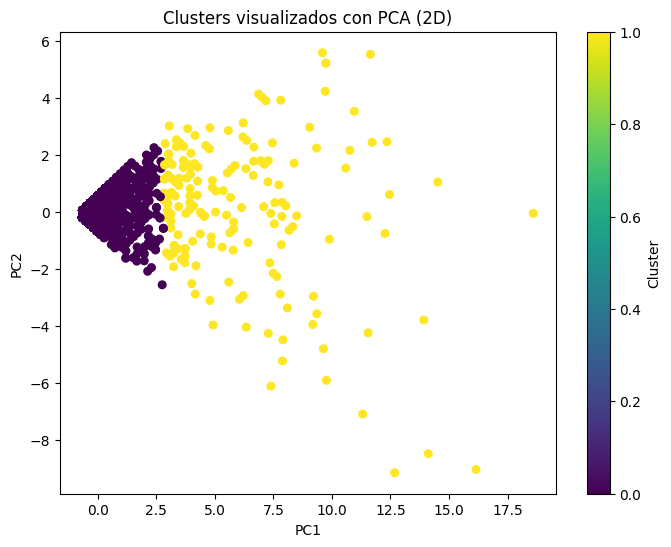

In [4]:
db_lib.reset_diagnoses_group_cluster(engine)

query_diagnoses = db_lib.get_newborn_diagnoses_query(0)

# Get Dataframe from a PostgreSQL Query
df_diagnoses = pd.read_sql(query_diagnoses, engine) 

n_clusters = hallar_kmeans(df_diagnoses)

features = ["diagnoses", "no_death", "death"]
    
# Subset de columnas que vamos a usar
X = df_diagnoses[features].copy()
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_diagnoses[features])

# --- Preprocesamiento ---
preprocess = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), features),            
    ]
)

kmeans = Pipeline(steps=[
    ('preprocess', preprocess),
    ('cluster', KMeans(
        n_clusters=n_clusters,
        init='k-means++',
        random_state=42,
        n_init=10
    ))
])
    
# Ajustar y obtener labels
labels = kmeans.fit_predict(X)

df_diagnoses['cluster'] = labels

# Obtener datos transformados para el silhouette
X_trans = kmeans.named_steps['preprocess'].transform(X)

# Update diagnoses group cluster
db_lib.update_diagnoses_group_cluster(engine, df_diagnoses)

pca = PCA(n_components=2)
components = pca.fit_transform(X_trans)

plt.figure(figsize=(8,6))
plt.scatter(components[:,0], components[:,1], c=labels, cmap='viridis', s=30)
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Clusters visualizados con PCA (2D)")
plt.colorbar(label="Cluster")
plt.show()

#### **2.6 Dataset Assembly**

Once the neonatal cohort, the clinical measurements, and the diagnostic group indicators were fully constructed, all features were consolidated into a single analysis-ready table: `mimiciv.cohort_newborn_dataset`.

The dataset is built from a three-level nested query over MIMIC-IV. The innermost subquery (`X`) identifies, for each eligible patient in `mimiciv.patients`, the relevant hospital admission (`hadm_id`) within a 45-day window before the date of birth, prioritising admissions with at least one associated ICU stay. The intermediate subquery (`Y`) enriches each record with admission-level attributes — ethnicity, insurance, language, admission type and location — and computes derived features: ICU stay flag (`icu_stay`), ICU stay count (`icu_stay_count`), total diagnosis count (`diagnoses_count`), and the binary mortality outcome (`outcome`). The outermost subquery (`K`) extracts 24 clinical measurements from `mimiciv.chartevents`, each captured at the **earliest available charttime** during the ICU stay, covering:

- **Haemodynamics:** heart rate, respiratory rate, O₂ saturation, mean/systolic/diastolic blood pressure
- **Anthropometrics:** weight at admission, height, temperature
- **Laboratory — electrolytes and metabolites:** glucose, haemoglobin, sodium, potassium, non-ionised calcium, magnesium, chloride, bicarbonate, phosphorus, creatinine, haematocrit, lactic acid
- **Neurological and respiratory:** apnea interval, GCS (eye, verbal, motor), Richmond Agitation-Sedation Scale (RASS), PEEP set, anion gap

```sql
create table mimiciv.cohort_newborn_dataset as
select K.*
from
(
	select Y.subject_id
	       , Y.hadm_id
	       , Y.stay_id
	       , Y.dob
	       , Y.gender
	       , Y.admission_count
	       , Y.ethnicity
	       , Y.insurance
	       , Y.language
	       , Y.admission_type
	       , Y.admission_location
	       , Y.icu_stay
	       , Y.icu_stay_count
	       , Y.diagnoses_count
	       , Y.deathtime
	       , Y.outcome
		   , (
			    select max(c.valuenum)
			    from   mimiciv.chartevents c
			    where  c.subject_id = Y.subject_id
			    and    c.hadm_id    = Y.hadm_id
			    and    c.stay_id    = Y.stay_id
			    and    c.itemid     = 220045
			    and    c.valuenum is not null
			    and    c.charttime = (
			    					 select min(c2.charttime)
			                         from   mimiciv.chartevents c2
								     where  c2.subject_id = c.subject_id
								     and    c2.hadm_id    = c.hadm_id
								     and    c2.stay_id    = c.stay_id
								     and    c2.itemid     = 220045
								     and    c2.valuenum is not null
								    )
			 ) as heart_rate
		   , (
            	select max(c.valuenum)
           	 	from   mimiciv.chartevents c
            	where  c.subject_id = Y.subject_id
            	and    c.hadm_id    = Y.hadm_id
            	and    c.stay_id    = Y.stay_id
            	and    c.itemid     = 220210
            	and    c.valuenum is not null
            	and    c.charttime = (
			    					 select min(c2.charttime)
			                         from   mimiciv.chartevents c2
								     where  c2.subject_id = c.subject_id
								     and    c2.hadm_id    = c.hadm_id
								     and    c2.stay_id    = c.stay_id
								     and    c2.itemid     = 220210
								     and    c2.valuenum is not null
								    )
           	 ) as  Respiratory_rate
           , (
            	select max(c.valuenum)
            	from   mimiciv.chartevents c
            	where  c.subject_id = Y.subject_id
            	and    c.hadm_id    = Y.hadm_id
            	and    c.stay_id    = Y.stay_id
            	and    c.itemid     = 220277
            	and    c.valuenum is not null
            	and    c.charttime = (
			    					 select min(c2.charttime)
			                         from   mimiciv.chartevents c2
								     where  c2.subject_id = c.subject_id
								     and    c2.hadm_id    = c.hadm_id
								     and    c2.stay_id    = c.stay_id
								     and    c2.itemid     = 220277
								     and    c2.valuenum is not null
								    )
           	 ) as  O2_Saturation
           , (
            	select max(c.valuenum)
            	from   mimiciv.chartevents c
            	where  c.subject_id = Y.subject_id
            	and    c.hadm_id    = Y.hadm_id
            	and    c.stay_id    = Y.stay_id
            	and    c.itemid     = 220181
            	and    c.valuenum is not null
            	and    c.charttime = (
			    					 select min(c2.charttime)
			                         from   mimiciv.chartevents c2
								     where  c2.subject_id = c.subject_id
								     and    c2.hadm_id    = c.hadm_id
								     and    c2.stay_id    = c.stay_id
								     and    c2.itemid     = 220181
								     and    c2.valuenum is not null
								    )
             ) as Pressure_blood_mean
            , (
            	select max(c.valuenum)
            	from   mimiciv.chartevents c
            	where  c.subject_id = Y.subject_id
            	and    c.hadm_id    = Y.hadm_id
            	and    c.stay_id    = Y.stay_id
            	and    c.itemid     = 220179
            	and    c.valuenum is not null
            	and    c.charttime = (
			    					 select min(c2.charttime)
			                         from   mimiciv.chartevents c2
								     where  c2.subject_id = c.subject_id
								     and    c2.hadm_id    = c.hadm_id
								     and    c2.stay_id    = c.stay_id
								     and    c2.itemid     = 220179
								     and    c2.valuenum is not null
								    )
             ) as Pressure_blood_Systolic
            , (
            	select max(c.valuenum)
            	from   mimiciv.chartevents c
            	where  c.subject_id = Y.subject_id
            	and    c.hadm_id    = Y.hadm_id
            	and    c.stay_id    = Y.stay_id
            	and    c.itemid     = 220180
            	and    c.valuenum is not null
            	and    c.charttime = (
			    					 select min(c2.charttime)
			                         from   mimiciv.chartevents c2
								     where  c2.subject_id = c.subject_id
								     and    c2.hadm_id    = c.hadm_id
								     and    c2.stay_id    = c.stay_id
								     and    c2.itemid     = 220180
								     and    c2.valuenum is not null
								    )
             ) as Pressure_blood_Diastolic
             , (
            	select max(c.valuenum)
            	from   mimiciv.chartevents c
            	where  c.subject_id = Y.subject_id
            	and    c.hadm_id    = Y.hadm_id
            	and    c.stay_id    = Y.stay_id
            	and    c.itemid     = 223761
            	and    c.valuenum is not null
            	and    c.charttime = (
			    					 select min(c2.charttime)
			                         from   mimiciv.chartevents c2
								     where  c2.subject_id = c.subject_id
								     and    c2.hadm_id    = c.hadm_id
								     and    c2.stay_id    = c.stay_id
								     and    c2.itemid     = 223761
								     and    c2.valuenum is not null
								    )
           	   ) as temperature_fahrenheit
           	 , (
	            select max(c.valuenum)
	            from   mimiciv.chartevents c
	            where  c.subject_id = Y.subject_id
	            and    c.hadm_id    = Y.hadm_id
	            and    c.stay_id    = Y.stay_id
	            and    c.itemid     = 226512
	            and    c.valuenum is not null
	            and    c.charttime = (
			    					 select min(c2.charttime)
			                         from   mimiciv.chartevents c2
								     where  c2.subject_id = c.subject_id
								     and    c2.hadm_id    = c.hadm_id
								     and    c2.stay_id    = c.stay_id
								     and    c2.itemid     = 226512
								     and    c2.valuenum is not null
								    )
	           ) as weight_admission
	         , (
	            select max(c.valuenum)
	            from   mimiciv.chartevents c
	            where  c.subject_id = Y.subject_id
	            and    c.hadm_id    = Y.hadm_id
	            and    c.stay_id    = Y.stay_id
	            and    c.itemid     = 220621
	            and    c.valuenum is not null
	            and    c.charttime = (
			    					 select min(c2.charttime)
			                         from   mimiciv.chartevents c2
								     where  c2.subject_id = c.subject_id
								     and    c2.hadm_id    = c.hadm_id
								     and    c2.stay_id    = c.stay_id
								     and    c2.itemid     = 220621
								     and    c2.valuenum is not null
								    )
	           ) as glucose
	         , (
	            select max(c.valuenum)
	            from   mimiciv.chartevents c
	            where  c.subject_id = Y.subject_id
	            and    c.hadm_id    = Y.hadm_id
	            and    c.stay_id    = Y.stay_id
	            and    c.itemid     = 220228
	            and    c.valuenum is not null
	            and    c.charttime = (
			    					 select min(c2.charttime)
			                         from   mimiciv.chartevents c2
								     where  c2.subject_id = c.subject_id
								     and    c2.hadm_id    = c.hadm_id
								     and    c2.stay_id    = c.stay_id
								     and    c2.itemid     = 220228
								     and    c2.valuenum is not null
								    )
	           ) as hemoglobine
	         , (
	            select max(c.valuenum)
	            from   mimiciv.chartevents c
	            where  c.subject_id = Y.subject_id
	            and    c.hadm_id    = Y.hadm_id
	            and    c.stay_id    = Y.stay_id
	            and    c.itemid     = 220645
	            and    c.valuenum is not null
	            and    c.charttime = (
			    					 select min(c2.charttime)
			                         from   mimiciv.chartevents c2
								     where  c2.subject_id = c.subject_id
								     and    c2.hadm_id    = c.hadm_id
								     and    c2.stay_id    = c.stay_id
								     and    c2.itemid     = 220645
								     and    c2.valuenum is not null
								    )
	           ) as sodium
	         , (
	            select max(c.valuenum)
	            from   mimiciv.chartevents c
	            where  c.subject_id = Y.subject_id
	            and    c.hadm_id    = Y.hadm_id
	            and    c.stay_id    = Y.stay_id
	            and    c.itemid     = 227442
	            and    c.valuenum is not null
	            and    c.charttime = (
			    					 select min(c2.charttime)
			                         from   mimiciv.chartevents c2
								     where  c2.subject_id = c.subject_id
								     and    c2.hadm_id    = c.hadm_id
								     and    c2.stay_id    = c.stay_id
								     and    c2.itemid     = 227442
								     and    c2.valuenum is not null
								    )
	           ) as potassium
	         , (
	            select max(c.valuenum)
	            from   mimiciv.chartevents c
	            where  c.subject_id = Y.subject_id
	            and    c.hadm_id    = Y.hadm_id
	            and    c.stay_id    = Y.stay_id
	            and    c.itemid     = 225625
	            and    c.valuenum is not null
	            and    c.charttime = (
			    					 select min(c2.charttime)
			                         from   mimiciv.chartevents c2
								     where  c2.subject_id = c.subject_id
								     and    c2.hadm_id    = c.hadm_id
								     and    c2.stay_id    = c.stay_id
								     and    c2.itemid     = 225625
								     and    c2.valuenum is not null
								    )
	           ) as noionized_calcium
	         , (
	            select max(c.valuenum)
	            from   mimiciv.chartevents c
	            where  c.subject_id = Y.subject_id
	            and    c.hadm_id    = Y.hadm_id
	            and    c.stay_id    = Y.stay_id
	            and    c.itemid     = 220635
	            and    c.valuenum is not null
	            and    c.charttime = (
			    					 select min(c2.charttime)
			                         from   mimiciv.chartevents c2
								     where  c2.subject_id = c.subject_id
								     and    c2.hadm_id    = c.hadm_id
								     and    c2.stay_id    = c.stay_id
								     and    c2.itemid     = 220635
								     and    c2.valuenum is not null
								    )
	           ) as magnesium
	         , (
	            select max(c.valuenum)
	            from   mimiciv.chartevents c
	            where  c.subject_id = Y.subject_id
	            and    c.hadm_id    = Y.hadm_id
	            and    c.stay_id    = Y.stay_id
	            and    c.itemid     = 220602
	            and    c.valuenum is not null
	            and    c.charttime = (
			    					 select min(c2.charttime)
			                         from   mimiciv.chartevents c2
								     where  c2.subject_id = c.subject_id
								     and    c2.hadm_id    = c.hadm_id
								     and    c2.stay_id    = c.stay_id
								     and    c2.itemid     = 220602
								     and    c2.valuenum is not null
								    )
	           ) as chloride
	         , (
	            select max(c.valuenum)
	            from   mimiciv.chartevents c
	            where  c.subject_id = Y.subject_id
	            and    c.hadm_id    = Y.hadm_id
	            and    c.stay_id    = Y.stay_id
	            and    c.itemid     = 227443
	            and    c.valuenum is not null
	            and    c.charttime = (
			    					 select min(c2.charttime)
			                         from   mimiciv.chartevents c2
								     where  c2.subject_id = c.subject_id
								     and    c2.hadm_id    = c.hadm_id
								     and    c2.stay_id    = c.stay_id
								     and    c2.itemid     = 227443
								     and    c2.valuenum is not null
								    )
	           ) as bicarbonate
	         , (
	            select max(c.valuenum)
	            from   mimiciv.chartevents c
	            where  c.subject_id = Y.subject_id
	            and    c.hadm_id    = Y.hadm_id
	            and    c.stay_id    = Y.stay_id
	            and    c.itemid     = 225677
	            and    c.valuenum is not null
	            and    c.charttime = (
			    					 select min(c2.charttime)
			                         from   mimiciv.chartevents c2
								     where  c2.subject_id = c.subject_id
								     and    c2.hadm_id    = c.hadm_id
								     and    c2.stay_id    = c.stay_id
								     and    c2.itemid     = 225677
								     and    c2.valuenum is not null
								    )
	           ) as phosphorus
	         , (
	            select max(c.valuenum)
	            from   mimiciv.chartevents c
	            where  c.subject_id = Y.subject_id
	            and    c.hadm_id    = Y.hadm_id
	            and    c.stay_id    = Y.stay_id
	            and    c.itemid     = 220615
	            and    c.valuenum is not null
	            and    c.charttime = (
			    					 select min(c2.charttime)
			                         from   mimiciv.chartevents c2
								     where  c2.subject_id = c.subject_id
								     and    c2.hadm_id    = c.hadm_id
								     and    c2.stay_id    = c.stay_id
								     and    c2.itemid     = 220615
								     and    c2.valuenum is not null
								    )
	           ) as creatine
	         , (
	            select max(c.valuenum)
	            from   mimiciv.chartevents c
	            where  c.subject_id = Y.subject_id
	            and    c.hadm_id    = Y.hadm_id
	            and    c.stay_id    = Y.stay_id
	            and    c.itemid     = 220545
	            and    c.valuenum is not null
	            and    c.charttime = (
			    					 select min(c2.charttime)
			                         from   mimiciv.chartevents c2
								     where  c2.subject_id = c.subject_id
								     and    c2.hadm_id    = c.hadm_id
								     and    c2.stay_id    = c.stay_id
								     and    c2.itemid     = 220545
								     and    c2.valuenum is not null
								    )
	           ) as hematrocit
	         , (
	            select max(c.valuenum)
	            from   mimiciv.chartevents c
	            where  c.subject_id = Y.subject_id
	            and    c.hadm_id    = Y.hadm_id
	            and    c.stay_id    = Y.stay_id
	            and    c.itemid     = 225668
	            and    c.valuenum is not null
	            and    c.charttime = (
			    					 select min(c2.charttime)
			                         from   mimiciv.chartevents c2
								     where  c2.subject_id = c.subject_id
								     and    c2.hadm_id    = c.hadm_id
								     and    c2.stay_id    = c.stay_id
								     and    c2.itemid     = 225668
								     and    c2.valuenum is not null
								    )
	           ) as lactic_acid
	         , (
	            select max(c.valuenum)
	            from   mimiciv.chartevents c
	            where  c.subject_id = Y.subject_id
	            and    c.hadm_id    = Y.hadm_id
	            and    c.stay_id    = Y.stay_id
	            and    c.itemid     = 223876
	            and    c.valuenum is not null
	            and    c.charttime = (
			    					 select min(c2.charttime)
			                         from   mimiciv.chartevents c2
								     where  c2.subject_id = c.subject_id
								     and    c2.hadm_id    = c.hadm_id
								     and    c2.stay_id    = c.stay_id
								     and    c2.itemid     = 223876
								     and    c2.valuenum is not null
								    )
	           ) as apnea_interval
	         , (
	            select max(c.valuenum)
	            from   mimiciv.chartevents c
	            where  c.subject_id = Y.subject_id
	            and    c.hadm_id    = Y.hadm_id
	            and    c.stay_id    = Y.stay_id
	            and    c.itemid     = 220739
	            and    c.valuenum is not null
	            and    c.charttime = (
			    					 select min(c2.charttime)
			                         from   mimiciv.chartevents c2
								     where  c2.subject_id = c.subject_id
								     and    c2.hadm_id    = c.hadm_id
								     and    c2.stay_id    = c.stay_id
								     and    c2.itemid     = 220739
								     and    c2.valuenum is not null
								    )
	           ) as gcs_eye_opening
	         , (
	            select max(c.valuenum)
	            from   mimiciv.chartevents c
	            where  c.subject_id = Y.subject_id
	            and    c.hadm_id    = Y.hadm_id
	            and    c.stay_id    = Y.stay_id
	            and    c.itemid     = 223900
	            and    c.valuenum is not null
	            and    c.charttime = (
			    					 select min(c2.charttime)
			                         from   mimiciv.chartevents c2
								     where  c2.subject_id = c.subject_id
								     and    c2.hadm_id    = c.hadm_id
								     and    c2.stay_id    = c.stay_id
								     and    c2.itemid     = 223900
								     and    c2.valuenum is not null
								    )
	           ) as gcs_verbal_response
	         , (
	            select max(c.valuenum)
	            from   mimiciv.chartevents c
	            where  c.subject_id = Y.subject_id
	            and    c.hadm_id    = Y.hadm_id
	            and    c.stay_id    = Y.stay_id
	            and    c.itemid     = 223901
	            and    c.valuenum is not null
	            and    c.charttime = (
			    					 select min(c2.charttime)
			                         from   mimiciv.chartevents c2
								     where  c2.subject_id = c.subject_id
								     and    c2.hadm_id    = c.hadm_id
								     and    c2.stay_id    = c.stay_id
								     and    c2.itemid     = 223901
								     and    c2.valuenum is not null
								    )
	           ) as gcs_motor_response
	         , (
	            select max(c.valuenum)
	            from   mimiciv.chartevents c
	            where  c.subject_id = Y.subject_id
	            and    c.hadm_id    = Y.hadm_id
	            and    c.stay_id    = Y.stay_id
	            and    c.itemid     = 228096
	            and    c.valuenum is not null
	            and    c.charttime = (
			    					 select min(c2.charttime)
			                         from   mimiciv.chartevents c2
								     where  c2.subject_id = c.subject_id
								     and    c2.hadm_id    = c.hadm_id
								     and    c2.stay_id    = c.stay_id
								     and    c2.itemid     = 228096
								     and    c2.valuenum is not null
								    )
	           ) as richmond_ras_scale
	         , (
	            select max(c.valuenum)
	            from   mimiciv.chartevents c
	            where  c.subject_id = Y.subject_id
	            and    c.hadm_id    = Y.hadm_id
	            and    c.stay_id    = Y.stay_id
	            and    c.itemid     = 220339
	            and    c.valuenum is not null
	            and    c.charttime = (
			    					 select min(c2.charttime)
			                         from   mimiciv.chartevents c2
								     where  c2.subject_id = c.subject_id
								     and    c2.hadm_id    = c.hadm_id
								     and    c2.stay_id    = c.stay_id
								     and    c2.itemid     = 220339
								     and    c2.valuenum is not null
								    )
	           ) as peep_set
	         , (
	            select max(c.valuenum)
	            from   mimiciv.chartevents c
	            where  c.subject_id = Y.subject_id
	            and    c.hadm_id    = Y.hadm_id
	            and    c.stay_id    = Y.stay_id
	            and    c.itemid     = 226730
	            and    c.valuenum is not null
	            and    c.charttime = (
			    					 select min(c2.charttime)
			                         from   mimiciv.chartevents c2
								     where  c2.subject_id = c.subject_id
								     and    c2.hadm_id    = c.hadm_id
								     and    c2.stay_id    = c.stay_id
								     and    c2.itemid     = 226730
								     and    c2.valuenum is not null
								    )
	           ) as height
	         , (
	            select max(c.valuenum)
	            from   mimiciv.chartevents c
	            where  c.subject_id = Y.subject_id
	            and    c.hadm_id    = Y.hadm_id
	            and    c.stay_id    = Y.stay_id
	            and    c.itemid     = 227073
	            and    c.valuenum is not null
	            and    c.charttime = (
			    					 select min(c2.charttime)
			                         from   mimiciv.chartevents c2
								     where  c2.subject_id = c.subject_id
								     and    c2.hadm_id    = c.hadm_id
								     and    c2.stay_id    = c.stay_id
								     and    c2.itemid     = 227073
								     and    c2.valuenum is not null
								    )
	           ) as anion_gap
	from
	(
		select X.subject_id
		       , X.hadm_id
		       , X.dob
		       , X.gender
		       , X.admission_count
		       , a3.ethnicity
		       , a3.insurance
		       , a3.language
		       , a3.admission_type
		       , a3.admission_location
		       , (
		          case when (
				          	select count(1)
				          	from   mimiciv.icustays i
				          	where  i.subject_id = X.subject_id
				          	and    i.hadm_id    = X.hadm_id
				          	and    DATE_PART('day', date_trunc('day',i.intime) - X.dob) between -45 and 0
				          	) > 0
				      then  1
				      else  0
				  end
				 ) as icu_stay
			   , (
			   		select min(i.stay_id)
				    from   mimiciv.icustays i
		          	where  i.subject_id = X.subject_id
		          	and    i.hadm_id    = X.hadm_id
		          	and    DATE_PART('day', date_trunc('day',i.intime) - X.dob) between -45 and 0
		         ) as stay_id
			   , (
			   		select count(1)
				    from   mimiciv.icustays i
		          	where  i.subject_id = X.subject_id
		          	and    i.hadm_id    = X.hadm_id
		          	and    DATE_PART('day', date_trunc('day',i.intime) - X.dob) between -45 and 0
		         ) as icu_stay_count
		       , (
		       		select count(1)
		       		from   mimiciv.diagnoses_icd di
		       		where  di.subject_id = X.subject_id
		       		and    di.hadm_id    = X.hadm_id
		         ) as diagnoses_count
		       , (
		          case when a3.deathtime is null
		          then (
		                select min(a5.deathtime)
		                from   mimiciv.admissions a5
		                where  a5.subject_id = a3.subject_id
		                and    a5.deathtime is not null
		               )
		          else a3.deathtime
		          end
		         ) deathtime
		       , (
		          case when a3.deathtime is null
		          then (
		                case when (
		                 			select min(a5.deathtime)
		                			from   mimiciv.admissions a5
		                			where  a5.subject_id = a3.subject_id
		                			and    a5.deathtime is not null
		               			  ) is not null
		               	     then 1
		               	     else 0
		               	end
		               	)
		          else 1
		          end
		         ) outcome
		from
		(
			select p.subject_id
			       , p.dob
			       , p.gender
			       , (
			       		select Count(1)
			         	from   mimiciv.admissions a1
			         	where  a1.subject_id = p.subject_id
			         	and    TO_CHAR(a1.admittime, 'YYYYMM') >= '210912'
				  	 	and    TO_CHAR(a1.admittime, 'YYYYMM')  <= '221410'
			         	and    DATE_PART('day', date_trunc('day',a1.admittime) - p.dob) between -45 and 0
			         ) as admission_count
			       , (
			          case when (
			       			   		select count(1)
						        	from   mimiciv.admissions a2
						        	join   mimiciv.icustays icu2
						        	on     a2.subject_id  = icu2.subject_id
						        	and    a2.hadm_id     = icu2.hadm_id
						        	where  icu2.subject_id = p.subject_id
						        	and    TO_CHAR(a2.admittime, 'YYYYMM') >= '210912'
						  	 		and    TO_CHAR(a2.admittime, 'YYYYMM')  <= '221410'
						  	 		and    DATE_PART('day', date_trunc('day',a2.admittime) - p.dob) between -45 and 0
						        	and    DATE_PART('day', date_trunc('day',icu2.intime) - p.dob) between -45 and 0
			       			  	) > 0
			               Then (
					         		select max(a2.hadm_id)
				          	 		from   mimiciv.admissions a2
				          	 		where  a2.subject_id = p.subject_id
				          	 		and    TO_CHAR(a2.admittime, 'YYYYMM') >= '210912'
						  	 		and    TO_CHAR(a2.admittime, 'YYYYMM')  <= '221410'
						  	 		and    DATE_PART('day', date_trunc('day',a2.admittime) - p.dob) between -45 and 0
						  	 		and    (
								          	select count(1)
								          	from   mimiciv.icustays icu2
								          	where  icu2.subject_id = a2.subject_id
								          	and    icu2.hadm_id    = a2.hadm_id
								          	and    DATE_PART('day', date_trunc('day',icu2.intime) - p.dob) between -45 and 0
									   		) > 0
						    	)
						   else (
									select max(a2.hadm_id)
				          	 		from   mimiciv.admissions a2
				          	 		where  a2.subject_id = p.subject_id
				          	 		and    TO_CHAR(a2.admittime, 'YYYYMM') >= '210912'
						  	 		and    TO_CHAR(a2.admittime, 'YYYYMM')  <= '221410'
						  	 		and    DATE_PART('day', date_trunc('day', a2.admittime) - p.dob) between -45 and 0
								)
					 end
		      		) as hadm_id
			from   mimiciv.patients p
			where  p.dob is not null
			and    TO_CHAR(p.dob, 'YYYYMM')  >= '211001'
			and    TO_CHAR(p.dob, 'YYYYMM')  <= '221410'
		) X
		join mimiciv.admissions a3
		on   a3.subject_id = X.subject_id
		and  a3.hadm_id    = X.hadm_id
		where X.hadm_id is not null
	) Y
) K;
```

After the base table was created, the 86 binary diagnostic group columns (`gdg_01`–`gdg_86`) were added

```
alter table mimiciv.cohort_newborn_dataset add column gdg_01 boolean; 
alter table mimiciv.cohort_newborn_dataset add column gdg_02 boolean; 
alter table mimiciv.cohort_newborn_dataset add column gdg_03 boolean; 
alter table mimiciv.cohort_newborn_dataset add column gdg_04 boolean; 
alter table mimiciv.cohort_newborn_dataset add column gdg_05 boolean; 
alter table mimiciv.cohort_newborn_dataset add column gdg_06 boolean; 
alter table mimiciv.cohort_newborn_dataset add column gdg_07 boolean; 
alter table mimiciv.cohort_newborn_dataset add column gdg_08 boolean; 
alter table mimiciv.cohort_newborn_dataset add column gdg_09 boolean; 
alter table mimiciv.cohort_newborn_dataset add column gdg_10 boolean; 
alter table mimiciv.cohort_newborn_dataset add column gdg_11 boolean; 
alter table mimiciv.cohort_newborn_dataset add column gdg_12 boolean; 
alter table mimiciv.cohort_newborn_dataset add column gdg_13 boolean; 
alter table mimiciv.cohort_newborn_dataset add column gdg_14 boolean; 
alter table mimiciv.cohort_newborn_dataset add column gdg_15 boolean; 
alter table mimiciv.cohort_newborn_dataset add column gdg_16 boolean; 
alter table mimiciv.cohort_newborn_dataset add column gdg_17 boolean; 
alter table mimiciv.cohort_newborn_dataset add column gdg_18 boolean; 
alter table mimiciv.cohort_newborn_dataset add column gdg_19 boolean; 
alter table mimiciv.cohort_newborn_dataset add column gdg_20 boolean; 
alter table mimiciv.cohort_newborn_dataset add column gdg_21 boolean; 
alter table mimiciv.cohort_newborn_dataset add column gdg_22 boolean; 
alter table mimiciv.cohort_newborn_dataset add column gdg_23 boolean; 
alter table mimiciv.cohort_newborn_dataset add column gdg_24 boolean; 
alter table mimiciv.cohort_newborn_dataset add column gdg_25 boolean; 
alter table mimiciv.cohort_newborn_dataset add column gdg_26 boolean; 
alter table mimiciv.cohort_newborn_dataset add column gdg_27 boolean; 
alter table mimiciv.cohort_newborn_dataset add column gdg_28 boolean; 
alter table mimiciv.cohort_newborn_dataset add column gdg_29 boolean; 
alter table mimiciv.cohort_newborn_dataset add column gdg_30 boolean; 
alter table mimiciv.cohort_newborn_dataset add column gdg_31 boolean; 
alter table mimiciv.cohort_newborn_dataset add column gdg_32 boolean; 
alter table mimiciv.cohort_newborn_dataset add column gdg_33 boolean; 
alter table mimiciv.cohort_newborn_dataset add column gdg_34 boolean; 
alter table mimiciv.cohort_newborn_dataset add column gdg_35 boolean; 
alter table mimiciv.cohort_newborn_dataset add column gdg_36 boolean; 
alter table mimiciv.cohort_newborn_dataset add column gdg_37 boolean; 
alter table mimiciv.cohort_newborn_dataset add column gdg_38 boolean; 
alter table mimiciv.cohort_newborn_dataset add column gdg_39 boolean; 
alter table mimiciv.cohort_newborn_dataset add column gdg_40 boolean; 
alter table mimiciv.cohort_newborn_dataset add column gdg_41 boolean; 
alter table mimiciv.cohort_newborn_dataset add column gdg_42 boolean; 
alter table mimiciv.cohort_newborn_dataset add column gdg_43 boolean; 
alter table mimiciv.cohort_newborn_dataset add column gdg_44 boolean; 
alter table mimiciv.cohort_newborn_dataset add column gdg_45 boolean; 
alter table mimiciv.cohort_newborn_dataset add column gdg_46 boolean; 
alter table mimiciv.cohort_newborn_dataset add column gdg_47 boolean; 
alter table mimiciv.cohort_newborn_dataset add column gdg_48 boolean; 
alter table mimiciv.cohort_newborn_dataset add column gdg_49 boolean; 
alter table mimiciv.cohort_newborn_dataset add column gdg_50 boolean; 
alter table mimiciv.cohort_newborn_dataset add column gdg_51 boolean; 
alter table mimiciv.cohort_newborn_dataset add column gdg_52 boolean; 
alter table mimiciv.cohort_newborn_dataset add column gdg_53 boolean; 
alter table mimiciv.cohort_newborn_dataset add column gdg_54 boolean; 
alter table mimiciv.cohort_newborn_dataset add column gdg_55 boolean; 
alter table mimiciv.cohort_newborn_dataset add column gdg_56 boolean; 
alter table mimiciv.cohort_newborn_dataset add column gdg_57 boolean; 
alter table mimiciv.cohort_newborn_dataset add column gdg_58 boolean; 
alter table mimiciv.cohort_newborn_dataset add column gdg_59 boolean; 
alter table mimiciv.cohort_newborn_dataset add column gdg_60 boolean; 
alter table mimiciv.cohort_newborn_dataset add column gdg_61 boolean; 
alter table mimiciv.cohort_newborn_dataset add column gdg_62 boolean; 
alter table mimiciv.cohort_newborn_dataset add column gdg_63 boolean; 
alter table mimiciv.cohort_newborn_dataset add column gdg_64 boolean; 
alter table mimiciv.cohort_newborn_dataset add column gdg_65 boolean; 
alter table mimiciv.cohort_newborn_dataset add column gdg_66 boolean; 
alter table mimiciv.cohort_newborn_dataset add column gdg_67 boolean; 
alter table mimiciv.cohort_newborn_dataset add column gdg_68 boolean; 
alter table mimiciv.cohort_newborn_dataset add column gdg_69 boolean; 
alter table mimiciv.cohort_newborn_dataset add column gdg_70 boolean; 
alter table mimiciv.cohort_newborn_dataset add column gdg_71 boolean; 
alter table mimiciv.cohort_newborn_dataset add column gdg_72 boolean; 
alter table mimiciv.cohort_newborn_dataset add column gdg_73 boolean; 
alter table mimiciv.cohort_newborn_dataset add column gdg_74 boolean; 
alter table mimiciv.cohort_newborn_dataset add column gdg_75 boolean; 
alter table mimiciv.cohort_newborn_dataset add column gdg_76 boolean; 
alter table mimiciv.cohort_newborn_dataset add column gdg_77 boolean; 
alter table mimiciv.cohort_newborn_dataset add column gdg_78 boolean; 
alter table mimiciv.cohort_newborn_dataset add column gdg_79 boolean; 
alter table mimiciv.cohort_newborn_dataset add column gdg_80 boolean; 
alter table mimiciv.cohort_newborn_dataset add column gdg_81 boolean; 
alter table mimiciv.cohort_newborn_dataset add column gdg_82 boolean; 
alter table mimiciv.cohort_newborn_dataset add column gdg_83 boolean; 
alter table mimiciv.cohort_newborn_dataset add column gdg_84 boolean; 
alter table mimiciv.cohort_newborn_dataset add column gdg_85 boolean; 
alter table mimiciv.cohort_newborn_dataset add column gdg_86 boolean; 
```

#### **2.7 Updating Diagnostic Features in the Dataset**

Once each ICD code in `cohort_newborn_diagnoses` has been assigned to a diagnostic group
(`GDG_01`–`GDG_84`, `GDG_85`, or `GDG_86`), the stored procedure
`mimiciv.update_feature_diagnoses_cohort_newborn_dataset()` is invoked to propagate
those assignments to the main dataset table (`cohort_newborn_dataset`).

The procedure iterates over each admission in the cohort and sets the corresponding
binary indicator columns (`gdg_01`–`gdg_86`) to `1` wherever at least one diagnosis
code belonging to that group was recorded for the patient.


In [5]:
db_lib.update_feature_diagnoses_dataset(engine)

Procedimiento ejecutado correctamente.


### **3. Load the dataset**

The analysis-ready table `mimiciv.cohort_newborn_dataset` — assembled in Section 2.6 and enriched with diagnostic group indicators in Section 2.7 — is loaded into a pandas DataFrame via the custom library function `get_newborn_cohort_query()`. The resulting DataFrame contains 20,982 records and 156 features prior to preprocessing.

In [6]:
query = db_lib.get_newborn_cohort_query()

# Get Dataframe from a PostgreSQL Query
df = pd.read_sql(query, engine)
print(f"Init Shape: {df.shape}")

Init Shape: (20982, 130)


### **4. Sentinel value and zero removal**

**Step 1 — Sentinel value 999,999.** The source system encodes missing numeric data with the placeholder 999,999. This value is replaced with `NaN` for `glucose`, `hemoglobine`, `noionized_calcium`, and `hematrocit` before any distributional analysis, as retaining it would distort outlier detection and imputation.

**Step 2 — Physiologically impossible zeros.** For 23 continuous variables where a reading of zero is clinically implausible (e.g., heart rate, oxygen saturation, blood pressures, weight), zero values are replaced with `NaN`. These sentinel zeros arise from system defaults or device initialisation errors and must be treated as missing rather than as true measurements.

In [7]:
cols_zero_impossible = [
    "heart_rate", "respiratory_rate", "o2_saturation",
    "pressure_blood_mean", "pressure_blood_systolic", "pressure_blood_diastolic",
    "temperature_fahrenheit", "weight_admission", "glucose", "hemoglobine",
    "sodium", "potassium", "noionized_calcium", "magnesium", "chloride",
    "bicarbonate", "phosphorus", "creatine", "hematrocit", "lactic_acid",
    "apnea_interval", "height", "peep_set"
]

for col in cols_zero_impossible:
    df[col] = df[col].replace(0, np.nan)

# Valores sentinel 999999 → NaN
for col in ["glucose", "hemoglobine", "noionized_calcium", "hematrocit"]:
    df[col] = df[col].replace(999999, np.nan)

### **5. Outlier Removal via IQR×3**

We apply a systematic criterion: **bounds = Q1 − 3×IQR / Q3 + 3×IQR** across all continuous numeric variables. The factor of 3 (instead of the classic 1.5) is conservative: it only removes clinically impossible extreme values.

**IQR (Interquartile Range)**: the difference between the 75th percentile (Q3) and the 25th percentile (Q1) of a distribution.

IQR = Q3 - Q1

- Lower bound = Q1 - 3 × IQR
- Upper bound = Q3 + 3 × IQR
- Any value outside these bounds is considered an extreme outlier and removed.
- The classic factor is ×1.5 (moderate outliers). Using ×3 is more conservative — it only removes values extremely far from the centre, which is appropriate for clinical data where natural variability is high.

In [8]:
numeric_lab_cols = [
    "heart_rate","respiratory_rate","o2_saturation",
    "pressure_blood_mean","pressure_blood_systolic","pressure_blood_diastolic",
    "temperature_fahrenheit","weight_admission","glucose","hemoglobine",
    "sodium","potassium","noionized_calcium","magnesium","chloride",
    "bicarbonate","phosphorus","creatine","hematrocit","lactic_acid",
    "apnea_interval","gcs_eye_opening","gcs_verbal_response","gcs_motor_response",
    "richmond_ras_scale","peep_set","height","anion_gap"
]

n_before = len(df)
outlier_report = []

clinical_min = {
    "heart_rate": 0,
    "respiratory_rate": 0,
    "o2_saturation": 0,
    "pressure_blood_mean": 0,
    "pressure_blood_systolic": 0,
    "pressure_blood_diastolic": 0,
    "temperature_fahrenheit": 90,   # hipotermia extrema
    "weight_admission": 0,
    "glucose": 0,
    "sodium": 100,
    "potassium": 0,
    "noionized_calcium": 0,
    "magnesium": 0,
    "chloride": 0,
    "bicarbonate": 0,
    "phosphorus": 0,
    "creatine": 0,
    "lactic_acid": 0,
}

for col in numeric_lab_cols:
    if col not in df.columns:
        continue
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lo_iqr = Q1 - 3 * IQR
    hi = Q3 + 3 * IQR
    
    # Apply minimum clinical threshold if defined
    lo = max(lo_iqr, clinical_min.get(col, lo_iqr))
    
    n_out = ((df[col] < lo) | (df[col] > hi)).sum()
    if n_out > 0:
        outlier_report.append({"column": col, "lower": round(lo,2), "upper": round(hi,2), "removed": n_out})
    df = df[(df[col].isna()) | ((df[col] >= lo) & (df[col] <= hi))]

print(f"Rows Deleted by outliers: {n_before - len(df)}  ({n_before} → {len(df)})")
pd.DataFrame(outlier_report)

Rows Deleted by outliers: 2301  (20982 → 18681)


,column,lower,upper,removed
0,heart_rate,0.0,198.0,2
1,respiratory_rate,0.0,49.0,31
2,o2_saturation,76.0,118.0,177
3,pressure_blood_mean,0.0,168.0,20
4,pressure_blood_systolic,0.0,245.0,2
5,pressure_blood_diastolic,0.0,151.0,12
6,temperature_fahrenheit,94.2,101.9,403
7,weight_admission,0.0,168.6,61
8,glucose,0.0,401.0,245
9,sodium,114.0,163.0,56


### **6. Imputation: median for skewed variables, mode for symmetric ones**

- Variables with |skew| > 1 receive the **median** (more robust to skewness).  
- Approximately symmetric variables receive the **mode** (most clinically frequent value).

In [9]:
# Calcule skewness post-cleanning
skew_df = df[numeric_lab_cols].skew().reset_index()
skew_df.columns = ["column","skew"]
skew_df["method"] = skew_df["skew"].apply(lambda s: "median" if abs(s) > 1 else "mode")
skew_df

,column,skew,method
0,heart_rate,0.425712,mode
1,respiratory_rate,0.713631,mode
2,o2_saturation,-1.598615,median
3,pressure_blood_mean,0.479265,mode
4,pressure_blood_systolic,0.311686,mode
5,pressure_blood_diastolic,0.652877,mode
6,temperature_fahrenheit,0.065987,mode
7,weight_admission,0.716886,mode
8,glucose,1.389327,median
9,hemoglobine,0.444184,mode


In [10]:
for _, row in skew_df.iterrows():
    col = row["column"]
    if col not in df.columns:
        continue
    if row["method"] == "median":
        fill_val = df[col].median()
    else:
        mode_series = df[col].mode()
        fill_val = mode_series.iloc[0] if not mode_series.empty else df[col].median()
    df[col] = df[col].fillna(fill_val)

print(df.isnull().sum()[df.isnull().sum() > 0])

stay_id      8032
deathtime    9145
insurance     291
language      123
dtype: int64


### **7. Categorical variable encoding**

Six categorical variable groups are one-hot encoded to convert them into numeric binary features compatible with the classifiers:

- **Gender**: two binary columns (`gender_F`, `gender_M`).
- **Ethnicity**: raw `ethnicity` values are first mapped to higher-level groups via an external lookup table (`ethnicity_groups.xlsx`), then one-hot encoded. The raw column is dropped.
- **Insurance**: five categories mapped to uppercase aliases (`MEDICAID`, `MEDICARE`, `NO_CHARGE`, `OTHERS`, `PRIVATE`).
- **Language**: mapped to language groups via `language_groups.xlsx`, then one-hot encoded.
- **Admission type** and **admission location**: one-hot encoded directly.

After encoding the final dataset contains **156 predictive features** plus the binary outcome `outcome`.

In [11]:
# Gender
df = pd.get_dummies(df, columns=["gender"])

# Ethnicity
df_ethnicity_groups = pd.read_excel("../data/ethnicity_groups.xlsx")
df = df.merge(df_ethnicity_groups, on="ethnicity", how="left")
df = pd.get_dummies(df, columns=["ethnicity_group"])
df = df.drop(columns=["ethnicity"])

# Insurance
df = pd.get_dummies(df, columns=["insurance"])
rename_map = {
    "insurance_Medicaid": "insurance_MEDICAID",
    "insurance_Medicare": "insurance_MEDICARE",
    "insurance_No charge": "insurance_NO_CHARGE",
    "insurance_Other": "insurance_OTHERS",
    "insurance_Private": "insurance_PRIVATE",
}
df = df.rename(columns={k:v for k,v in rename_map.items() if k in df.columns})

# Language
df_language_groups = pd.read_excel("../data/language_groups.xlsx")
df = df.merge(df_language_groups, on="language", how="left")
df = pd.get_dummies(df, columns=["language_group"])
df = df.drop(columns=["language"])

# Admission type
df = pd.get_dummies(df, columns=["admission_type"])
df.columns = [c.replace(" ","_") for c in df.columns]

# Admission location
df_admission_location_groups = pd.read_excel("../data/admission_location_groups.xlsx")
df = df.merge(df_admission_location_groups, on="admission_location", how="left")
df = pd.get_dummies(df, columns=["admission_location_group"])
df = df.drop(columns=["admission_location"])

print(f"Features tras encoding: {len(df.columns) - 6}")

Features tras encoding: 155


### **8. Review correlations between features**

A Pearson correlation matrix is computed over all numeric features (excluding identifier columns `subject_id`, `hadm_id`, and the outcome variable). Two correlation analyses are performed:

1. **Full feature correlation** — heatmap over all numeric variables to detect global multicollinearity.
2. **Diagnostic group correlation** — a focused analysis on the 86 binary `gdg_*` indicators, using a **threshold of |r| ≥ 0.70** to flag pairs with excessive overlap.

Feature pairs exceeding the threshold are inspected to determine whether one of the two features should be removed before training. Highly correlated diagnosis indicators (e.g., two groups sharing most of their constituent ICD codes) may introduce redundant signal and inflate variance in tree-based models. No features were removed at this stage given the relatively low inter-GDG correlation observed in the cohort.

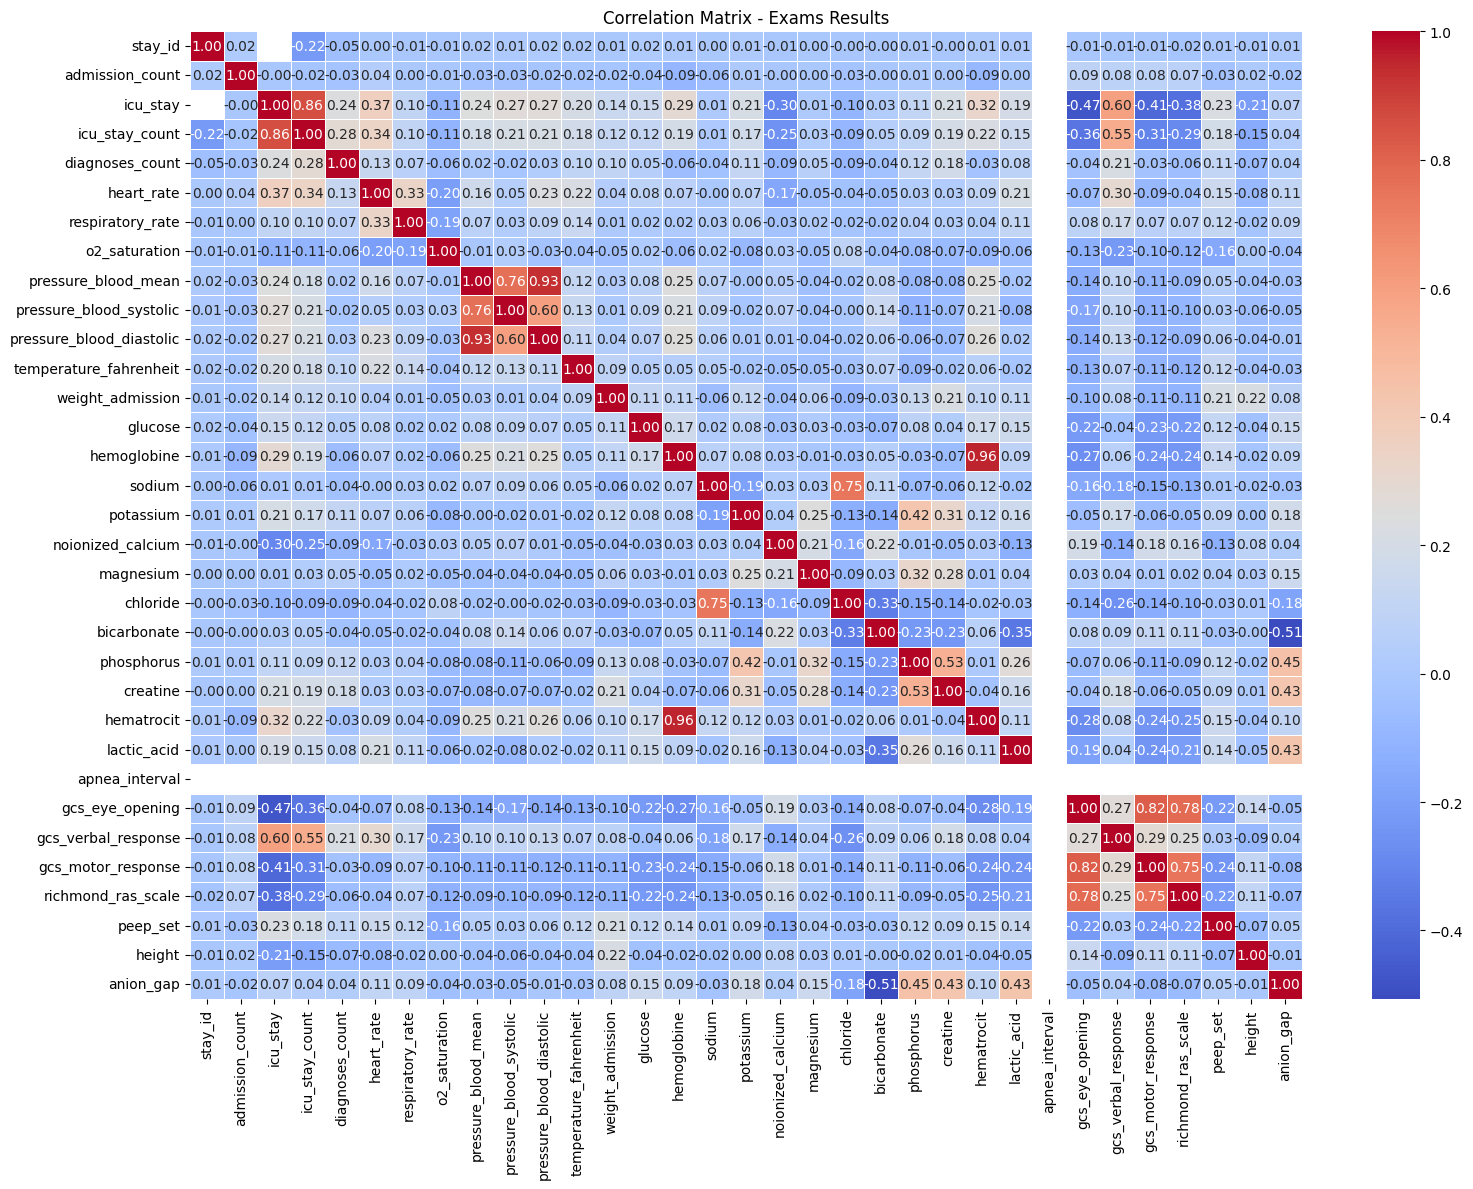

In [ ]:
# Exclude columns (Keys and Outcome)
excluded = ['subject_id', 'hadm_id', 'outcome']
df_correletion = df.drop(columns=excluded)

# Select numeric columns 
numeric_cols = df_correletion.select_dtypes(include='number')

# Create correlation matrix
correlation_matrix = numeric_cols.corr()

# Plot the correlation matrix on a heat map
plt.figure(figsize=(16, 12))
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap='coolwarm', linewidths=0.5)
plt.title('Correlation Matrix - Exams Results')
plt.tight_layout()
plt.savefig('../figures/Fig_Correlacion_Matrix_Exams_Results.pdf', format='pdf', bbox_inches='tight')
plt.savefig('../figures/Fig_Correlacion_Matrix_Exams_Results.png', format='png', dpi=300, bbox_inches='tight')
plt.show()


In [13]:
# Identify clinical measurement variable pairs with |r| >= 0.70
# (excluding GDG indicators and identifier/outcome columns)

gdg_cols  = [c for c in df.columns if c.startswith('gdg_')]
excl_cols = ['subject_id', 'hadm_id', 'stay_id', 'dob', 'deathtime', 'outcome'] + gdg_cols

df_clinical = df.drop(columns=[c for c in excl_cols if c in df.columns])
clinical_num = df_clinical.select_dtypes(include='number')

corr_clinical = clinical_num.corr()

# Upper triangle only, threshold 0.70
import numpy as np
mask_upper = np.triu(np.ones_like(corr_clinical, dtype=bool), k=1)
high_corr_pairs = (
    corr_clinical
    .where(mask_upper)
    .stack()
    .reset_index()
)
high_corr_pairs.columns = ['feature_1', 'feature_2', 'r']
high_corr_pairs = high_corr_pairs[abs(high_corr_pairs['r']) >= 0.70].sort_values('r', ascending=False)

print(f"Pairs with |r| >= 0.70 among clinical measurement variables: {len(high_corr_pairs)}")
print()
print(high_corr_pairs.to_string(index=False))


Pairs with |r| >= 0.70 among clinical measurement variables: 8

          feature_1                feature_2        r
        hemoglobine               hematrocit 0.955576
pressure_blood_mean pressure_blood_diastolic 0.933715
           icu_stay           icu_stay_count 0.860942
    gcs_eye_opening       gcs_motor_response 0.821936
    gcs_eye_opening       richmond_ras_scale 0.778235
pressure_blood_mean  pressure_blood_systolic 0.763041
 gcs_motor_response       richmond_ras_scale 0.749762
             sodium                 chloride 0.745659


#### **8.1 Correlation decision — clinical measurement variables**

The filtered analysis identified the following pairs of clinical measurement variables with |r| ≥ 0.70:

| Feature 1 | Feature 2 | r |
|---|---|---|
| `hemoglobine` | `hematrocit` | 0.96 |
| `pressure_blood_mean` | `pressure_blood_diastolic` | 0.93 |
| `pressure_blood_mean` | `pressure_blood_systolic` | 0.76 |

**Decision: all variables retained.**

These correlations reflect genuine physiological relationships rather than data artefacts:

- **Haemoglobin – Haematocrit**: both measure the oxygen-carrying capacity of blood via different but mathematically linked quantities (Hct ≈ 3 × Hb). Each carries independent clinical signal in neonatal monitoring.
- **Mean arterial pressure – Diastolic / Systolic**: MAP is a derived composite of SBP and DBP (MAP ≈ (SBP + 2×DBP) / 3). All three are routinely reported and interpreted separately in neonatal critical care.

From a modelling perspective, **Random Forest, XGBoost, and Extra Trees are not sensitive to multicollinearity** — each tree split is evaluated independently and redundant features are simply under-selected. The **Logistic Regression** base learner is protected by **L2 regularisation**, which shrinks the coefficients of correlated predictors proportionally without requiring manual removal. Removing one variable from each pair would discard clinically meaningful and independently monitored signals without improving model performance.


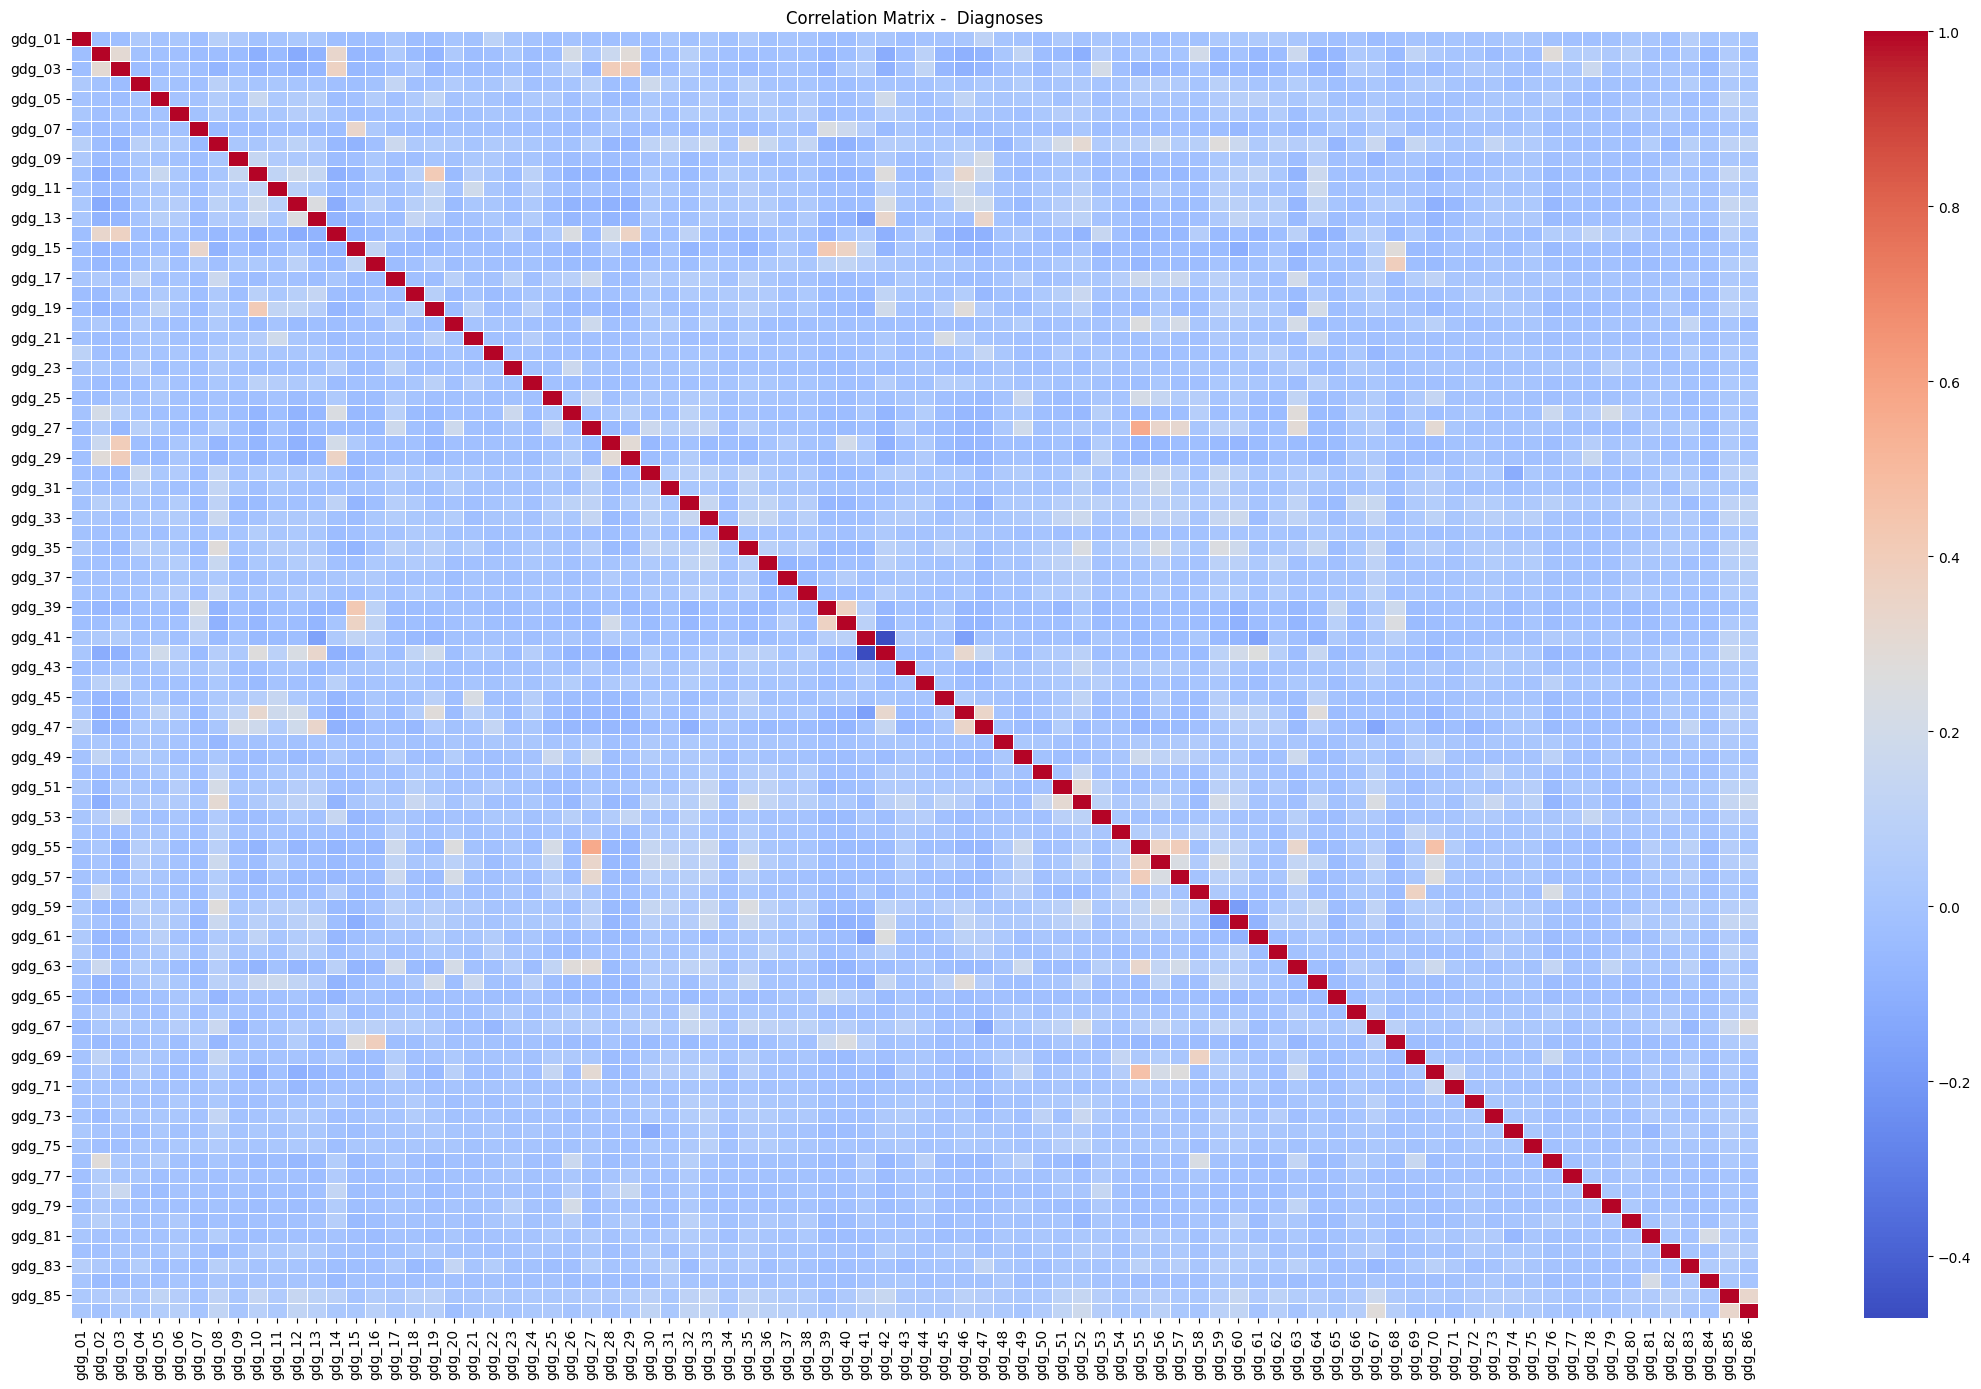

In [14]:
diagnosis_cols = [col for col in df.columns if col.startswith('gdg_') and df[col].dropna().isin([0, 1, True, False]).all()]

# Calcular la matriz de correlación
correlation_matrix = df[diagnosis_cols].corr()

# Visualizar con un mapa de calor
plt.figure(figsize=(22, 14))
sns.heatmap(correlation_matrix, cmap='coolwarm', annot=False, linewidths=0.5)
plt.title('Correlation Matrix -  Diagnoses')
plt.tight_layout()
plt.savefig('../figures/Fig_Correlacion_Matrix_Diagnoses.pdf', format='pdf', bbox_inches='tight')
plt.savefig('../figures/Fig_Correlacion_Matrix_Diagnoses.png', format='png', dpi=300, bbox_inches='tight')
plt.show()


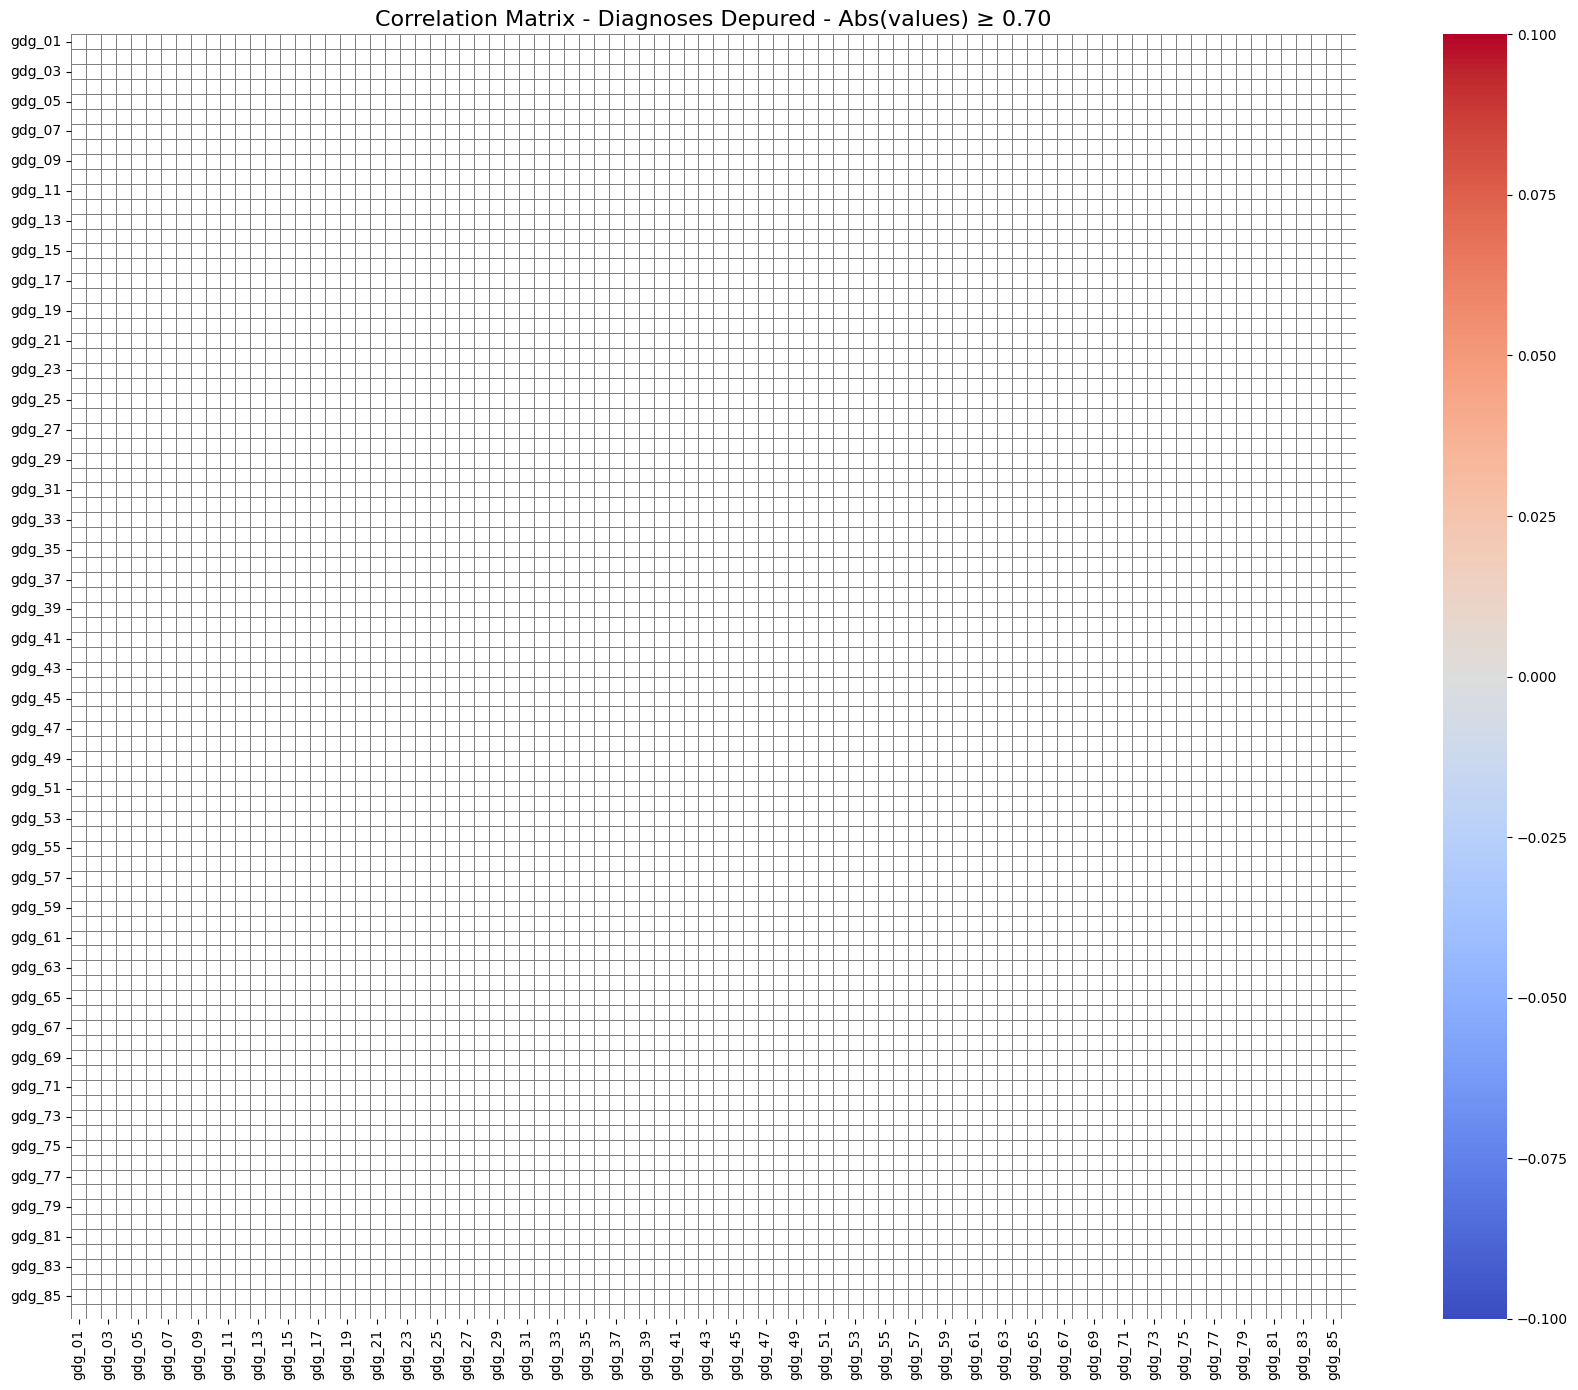

In [15]:
# Filtrar correlaciones mayores o iguales a 0.70 (excluyendo la diagonal)
filtered_corr = correlation_matrix.copy()

# Create a new matrix and only enable the upper triangular one
mask_upper = np.triu(np.ones_like(filtered_corr, dtype=bool))
filtered_corr = filtered_corr.mask(mask_upper)

# Filter correlations >= 0.70 y < 1.0
filtered_corr = filtered_corr.where((abs(filtered_corr) >= 0.70) & (abs(filtered_corr) < 1.0))

# Create mask to hide null values
mask_to_plot = filtered_corr.isnull()

# Delete warnings de matplotlib/numpy 
# (This happens when there are no correlations greater than 70% in the correlation matrix.)
with warnings.catch_warnings():
    warnings.simplefilter("ignore", category=RuntimeWarning)

    # Create graphics
    plt.figure(figsize=(18, 14))
    sns.heatmap(filtered_corr, mask=mask_to_plot, annot=True, fmt=".2f", cmap="coolwarm"
                , cbar=True, square=True, linewidths=0.5, linecolor='gray')
    plt.title("Correlation Matrix - Diagnoses Depured - Abs(values) ≥ 0.70", fontsize=16)
    plt.tight_layout()
    plt.savefig('../figures/Fig_Correlacion_Matrix_Diagnoses_Depured.pdf', format='pdf', bbox_inches='tight')
    plt.savefig('../figures/Fig_Correlacion_Matrix_Diagnoses_Depured.png', format='png', dpi=300, bbox_inches='tight')
    plt.show()

### **9. Scaling continuous variables**

Continuous variables span very different numerical ranges (e.g., heart rate in beats per minute vs. creatinine in mg/dL). Without normalisation, distance-based algorithms and regularised models assign disproportionate weight to high-magnitude variables. Two scaling strategies are applied based on the distributional shape of each variable.

##### **9.1. Data distribution — Histograms with density curve**

Distribution histograms with a kernel density estimate (KDE) overlay are plotted for every numeric feature in the dataset (excluding identifier and outcome columns). These plots inform the scaling decision in Section 9.2 by revealing skewness, bimodality, or heavy tails.

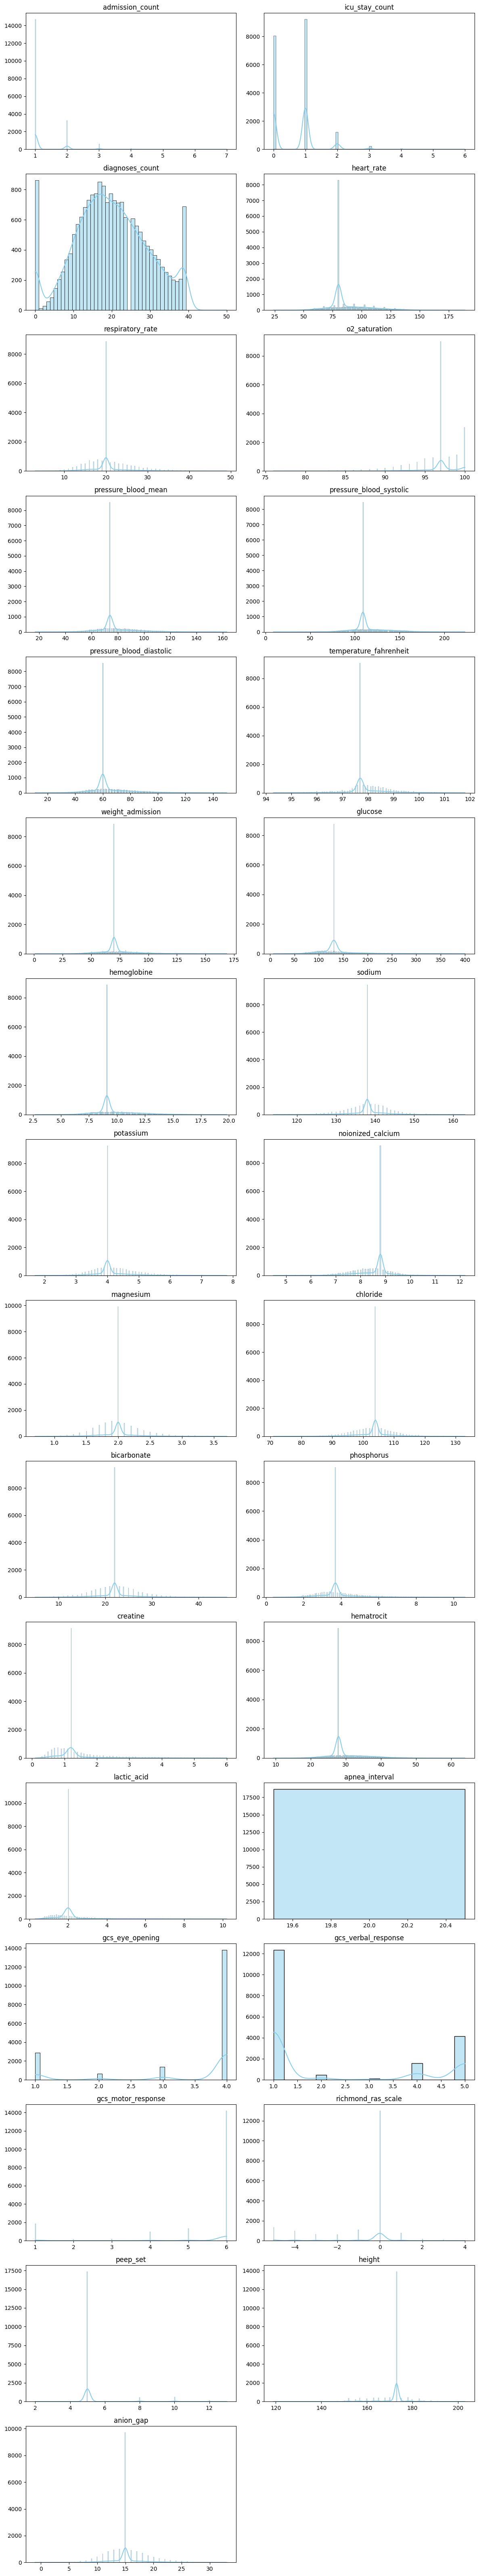

In [16]:
# Exclude columns (Keys and Outcome)
excluded_columns = ['subject_id', 'hadm_id', 'stay_id', 'outcome', 'icu_stay']
df_scalling = df.drop(columns=excluded_columns)

# Select numeric columns 
numeric_cols = df_scalling.select_dtypes(include='number').columns

# Configure subplots
cols_per_row = 2
total_plots = len(numeric_cols)
rows = math.ceil(total_plots / cols_per_row)
fig, axes = plt.subplots(rows, cols_per_row, figsize=(cols_per_row * 6, rows * 4))
axes = axes.flatten()

# Graph every column
for i, col in enumerate(numeric_cols):
    sns.histplot(df_scalling[col].dropna(), kde=True, ax=axes[i], color='skyblue')
    axes[i].set_title(col)
    axes[i].set_xlabel('')
    axes[i].set_ylabel('')

# drop empty subplot
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

##### **9.2. Define the scaling technique for each continuous feature**

A data-driven rule assigns the scaling technique per variable based on its **skewness coefficient**:

- `|skew| > 1` → **`RobustScaler`**: scales using the median and IQR, making it resistant to residual outliers in skewed distributions (e.g., lactic acid, creatinine, weight at admission).
- `|skew| ≤ 1` → **`MinMaxScaler`**: linearly maps the variable to [0, 1], suitable for approximately symmetric distributions (e.g., heart rate, sodium, blood pressures).

Scaled values are stored as new columns with the `_scaled` suffix, preserving the original values for audit purposes.

In [17]:
# Identify numeric columns
numeric_cols = df_scalling.select_dtypes(include=['number']).columns

# Function to recommend scaling technique
def recommend_scaling(df_scalling, col):
    if df_scalling[col].skew() > 1 or df_scalling[col].skew() < -1:
        return 'RobustScaler', df_scalling[col].skew(), df_scalling[col].max() - df_scalling[col].min() 
    else:
        return 'MinMaxScaler', df_scalling[col].skew(), df_scalling[col].max() - df_scalling[col].min() 

recommendations = []

# Populate the DataFrame with recommendations
for col in numeric_cols:
    #print (recommend_scaling(df_scalling, col))
    recomendation, skew, max_minus_min = recommend_scaling(df_scalling, col)
    recommendations.append({
                            'column': col
                            ,'technique': recomendation
                            ,'skew': skew
                            ,'max-min': max_minus_min
                            })

# Convert list in DataFrame
scaling_recommendations = pd.DataFrame(recommendations)

# Display the recommendations
scaling_recommendations

,column,technique,skew,max-min
0,admission_count,RobustScaler,2.377809,6.0
1,icu_stay_count,MinMaxScaler,0.969842,6.0
2,diagnoses_count,MinMaxScaler,0.043286,50.0
3,heart_rate,RobustScaler,1.270164,165.0
4,respiratory_rate,RobustScaler,1.191485,46.0
5,o2_saturation,RobustScaler,-2.369834,24.0
6,pressure_blood_mean,RobustScaler,1.203876,146.0
7,pressure_blood_systolic,RobustScaler,1.046855,214.0
8,pressure_blood_diastolic,RobustScaler,1.457354,139.0
9,temperature_fahrenheit,MinMaxScaler,0.639915,7.5


In [18]:
# Export Dataset
#df.to_excel('../data/df_cohort_newborn_dataset.xlsx', index=False)

#### **9.3. Scaling**

The recommended scaler for each variable is applied sequentially. Each continuous feature is transformed independently using `fit_transform` on the full dataset at this stage; note that in a strict pipeline the scaler would be fitted on the training partition only to avoid data leakage — this is enforced at the model-training stage via `GridSearchCV`.

In [19]:
# Crear una copia del DataFrame original para no modificarlo directamente
df_scaled = df.copy()

# Recorrer las recomendaciones
for _, row in scaling_recommendations.iterrows():

    col = row['column']
    method = row['technique']

    if method == 'StandardScaler':
        scaler = StandardScaler()
    elif method == 'MinMaxScaler':
        scaler = MinMaxScaler()
    elif method == 'RobustScaler':
        scaler = RobustScaler()
    else:
        continue # Saltar columnas que no necesitan escalado

    # Aplicar el escalado y reemplazar la columna
    df_scaled[col + '_scaled'] = scaler.fit_transform(df[[col]])

# Mostrar algunas columnas escaladas
df_scaled[[col + '_scaled' for col in scaling_recommendations['column'].head(5)]].head()

,admission_count_scaled,icu_stay_count_scaled,diagnoses_count_scaled,heart_rate_scaled,respiratory_rate_scaled
0,1.0,0.166667,0.32,3.600000,0.0
1,0.0,0.000000,0.26,0.000000,0.0
2,0.0,0.166667,0.64,-0.733333,0.5
3,1.0,0.000000,0.50,0.000000,0.0
4,0.0,0.333333,0.58,3.600000,1.5


In [20]:
#df_scaled.to_excel("../data/df_scaled_cohort_newborn_dataset.xlsx", index=False)
print("Scalling complete. Shape:", df_scaled.shape)

Scalling complete. Shape: (18681, 192)


### **10. Build model dataset**

The final model-ready DataFrame is assembled from `df_scaled` by dropping columns that must not enter the classifier:

- **Identifier columns** (`subject_id`, `hadm_id`, `stay_id`, `dob`, `deathtime`): administrative keys with no predictive value.
- **Unscaled raw numeric columns**: replaced by their `_scaled` counterparts.
- **`icu_stay`** binary flag: retained implicitly through the ICU-specific vital-sign variables.

The retained features comprise the **scaled continuous variables**, the **one-hot encoded categorical features**, the **84 expert-validated binary diagnostic group indicators** (`gdg_01`–`gdg_84`), and the two residual clustering indicators (`gdg_85`, `gdg_86`), yielding a total of **156 predictive features**. The `outcome` column is the target variable.

In [21]:
id_cols = ["subject_id","hadm_id","stay_id","dob","deathtime"]
raw_numeric = ["heart_rate","respiratory_rate","o2_saturation",
               "pressure_blood_mean","pressure_blood_systolic","pressure_blood_diastolic",
               "temperature_fahrenheit","weight_admission","glucose","hemoglobine",
               "sodium","potassium","noionized_calcium","magnesium","chloride",
               "bicarbonate","phosphorus","creatine","hematrocit","lactic_acid",
               "apnea_interval","gcs_eye_opening","gcs_verbal_response","gcs_motor_response",
               "richmond_ras_scale","peep_set","height","anion_gap",
               "icu_stay_count","admission_count"               
               ]
df_model = df_scaled.sort_values('subject_id').reset_index(drop=True)

col_to_drop = id_cols + [c for c in raw_numeric if c in df_scaled.columns]
df_model = df_model.drop(columns=[c for c in col_to_drop if c in df_scaled.columns])
df_model = df_model.reset_index(drop=True)

print(f"Model Features: {len(df_model.columns) - 1}")
print(df_model.columns.tolist())

Model Features: 156
['outcome', 'icu_stay', 'diagnoses_count', 'gdg_01', 'gdg_02', 'gdg_03', 'gdg_04', 'gdg_05', 'gdg_06', 'gdg_07', 'gdg_08', 'gdg_09', 'gdg_10', 'gdg_11', 'gdg_12', 'gdg_13', 'gdg_14', 'gdg_15', 'gdg_16', 'gdg_17', 'gdg_18', 'gdg_19', 'gdg_20', 'gdg_21', 'gdg_22', 'gdg_23', 'gdg_24', 'gdg_25', 'gdg_26', 'gdg_27', 'gdg_28', 'gdg_29', 'gdg_30', 'gdg_31', 'gdg_32', 'gdg_33', 'gdg_34', 'gdg_35', 'gdg_36', 'gdg_37', 'gdg_38', 'gdg_39', 'gdg_40', 'gdg_41', 'gdg_42', 'gdg_43', 'gdg_44', 'gdg_45', 'gdg_46', 'gdg_47', 'gdg_48', 'gdg_49', 'gdg_50', 'gdg_51', 'gdg_52', 'gdg_53', 'gdg_54', 'gdg_55', 'gdg_56', 'gdg_57', 'gdg_58', 'gdg_59', 'gdg_60', 'gdg_61', 'gdg_62', 'gdg_63', 'gdg_64', 'gdg_65', 'gdg_66', 'gdg_67', 'gdg_68', 'gdg_69', 'gdg_70', 'gdg_71', 'gdg_72', 'gdg_73', 'gdg_74', 'gdg_75', 'gdg_76', 'gdg_77', 'gdg_78', 'gdg_79', 'gdg_80', 'gdg_81', 'gdg_82', 'gdg_83', 'gdg_84', 'gdg_85', 'gdg_86', 'gender_F', 'gender_M', 'ethnicity_group_AFRO_DESC', 'ethnicity_group_ASIAN',

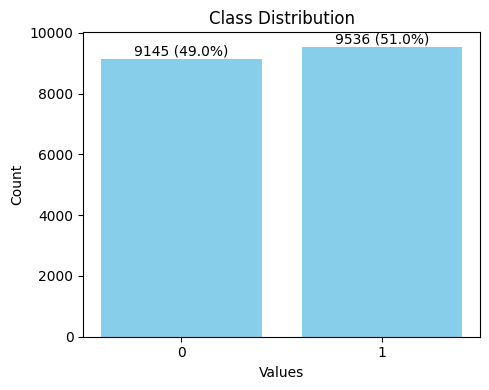

In [22]:
# Contar el número de registros por etiqueta
count_y = df_model['outcome'].value_counts().sort_index()

# Calcular el porcentaje
total = count_y.sum()
percentages = (count_y / total) * 100

# Crear la gráfica de barras
plt.figure(figsize=(5, 4))

bars = plt.bar(count_y.index.astype(str), count_y.values, color='skyblue')


for bar, cantidad, percentaje in zip(bars, count_y.values, percentages.values):
    plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height(),
                f'{cantidad} ({percentaje:.1f}%)',
                ha='center', va='bottom', fontsize=10
            )

plt.title('Class Distribution')
plt.xlabel('Values')
plt.ylabel('Count')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### **11. Train / Test Split**

The dataset is split into a training set (80%) and a held-out test set (20%) using `train_test_split` with:

- `test_size = 0.2` → 14,944 training records / 3,737 test records.
- `stratify = y` → preserves the class distribution (≈49% survived, ≈51% deceased) in both partitions, preventing imbalanced splits.
- `random_state = 42` → ensures reproducibility.

The test set is not used during any hyperparameter search or model selection step; it is reserved exclusively for final evaluation.

In [23]:
X = df_model.drop(columns=["outcome"])
y = df_model["outcome"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Train: {X_train.shape}  |  Test: {X_test.shape}")
print(f"Prevalencia positiva — Train: {y_train.mean():.3f}  |  Test: {y_test.mean():.3f}")

Train: (14944, 156)  |  Test: (3737, 156)
Prevalencia positiva — Train: 0.510  |  Test: 0.511


### **12. Run Models**

Each base classifier is trained using **`GridSearchCV`** with **5-fold stratified cross-validation** (`cv=5`), optimising for the **F1-score** (`scoring='f1'`). The search is parallelised across all available CPU cores (`n_jobs=-1`). The best estimator from each grid search is stored and passed to the stacking meta-learner in Section 12.5.

The helper function `run_model` encapsulates the grid search, extracts the best estimator, generates test-set predictions, and prints performance metrics. The ROC curve and AUC for each model are computed by `plot_roc` (defined in `libraries/functions.py`).

In [24]:
def run_model(p_model, p_param_grid, p_X_train, p_y_train, p_X_test, p_y_test, title_model, nombre_imagen):

    with open(os.devnull, 'w') as f, redirect_stdout(f):

        # Configurate GridSearchCV
        #grid_search = GridSearchCV(estimator= p_model, param_grid=p_param_grid, scoring='f1', cv=5, verbose=1, n_jobs=-1)
        grid_search = GridSearchCV(estimator= p_model
                                   , param_grid=p_param_grid
                                   , scoring='f1'
                                   , cv=5
                                   , verbose=1
                                   , n_jobs=-1
                                   )

        # Ajust the model
        grid_search.fit(p_X_train, p_y_train)

    # Best model
    best_model = grid_search.best_estimator_

    best_params_formatted = ', '.join(f'{key}: {value}' for key, value in grid_search.best_params_.items())

    # Predictions
    y_pred_model = best_model.predict(p_X_test)

    report_dict = classification_report(p_y_test, y_pred_model, output_dict=True)

    # Convert Dictionary to Dataframe
    report_df = pd.DataFrame(report_dict).transpose()

    # Round Values for best presentation
    report_df = report_df.round(2)

    # Create subplots
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    # Subplot 1: Heatmap del classification_report
    sns.heatmap(report_df.iloc[:-1, :-1], annot=True, cmap="YlGnBu", cbar=False, ax=axes[0])
    axes[0].set_title("Best hyperparams: " + best_params_formatted, fontsize=8)
    axes[0].set_ylabel("Classes")
    axes[0].set_xlabel("Metrics")
    axes[0].tick_params(axis='y', rotation=0)

    # Subplot 2: Confusion Matrix
    cm = confusion_matrix(p_y_test, y_pred_model)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=best_model.classes_)
    disp.plot(cmap='Blues', ax=axes[1], colorbar=False)
    axes[1].set_title("Confusion Matrix", fontsize=8)

    # General title
    fig.suptitle(title_model, fontsize=12, weight='bold')

    # Adjust design
    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.savefig("../figures/"+nombre_imagen +'.pdf', format='pdf', bbox_inches='tight')
    plt.savefig("../figures/"+nombre_imagen +'.png', format='png', dpi=300, bbox_inches='tight')
    plt.show()

    return best_model, y_pred_model 

def plot_roc(y_test, y_pred, title, nombre_imagen):
    fpr, tpr, _ = roc_curve(y_test, y_pred)
    roc_auc = auc(fpr, tpr)
    plt.figure(figsize=(5,4))
    plt.plot(fpr, tpr, label=f"AUC = {roc_auc:.3f}")
    plt.plot([0,1],[0,1],"k--")
    plt.xlabel("FPR"); plt.ylabel("TPR")
    plt.title(f"ROC — {title}")
    plt.legend()
    plt.tight_layout()
    plt.savefig("../figures/"+nombre_imagen +'.pdf', format='pdf', bbox_inches='tight')
    plt.savefig("../figures/"+nombre_imagen +'.png', format='png', dpi=300, bbox_inches='tight')
    plt.show()
    return roc_auc

#### **12.1. Random Forest**

A `RandomForestClassifier` with `class_weight="balanced_subsample"` is used to handle the near-balanced but slightly skewed class distribution. Key hyperparameters searched:

| Parameter | Values searched |
|---|---|
| `n_estimators` | 400 |
| `max_depth` | 30, 40, None |
| `min_samples_split` | 2, 5 |
| `min_samples_leaf` | 2, 4 |
| `max_features` | sqrt |

`balanced_subsample` recomputes class weights for each bootstrap sample, which is more appropriate than a global weight when trees are grown on bootstrapped subsets.

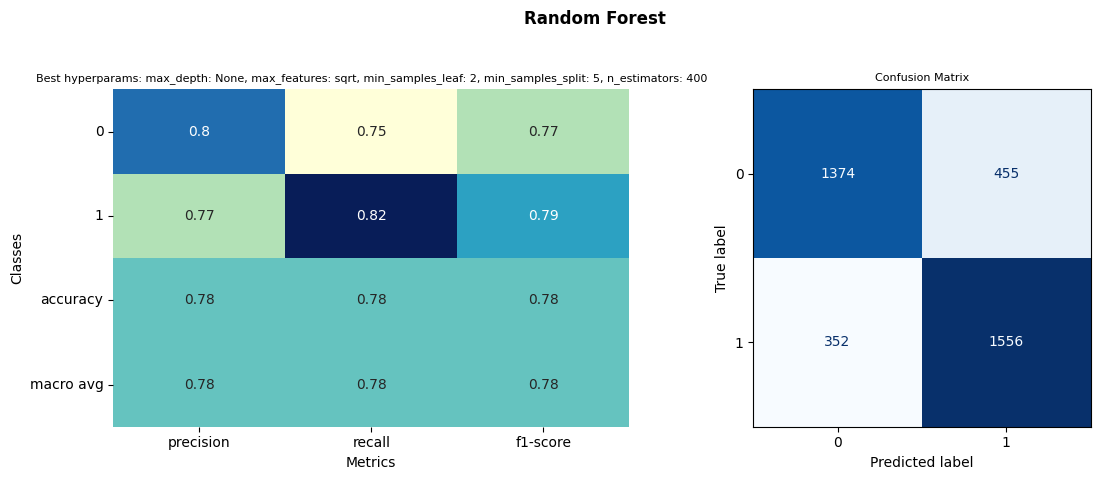

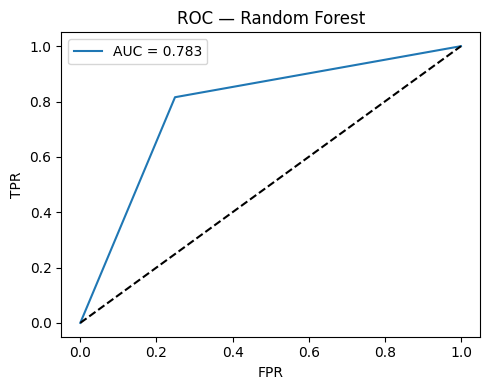

In [25]:
model_rf = RandomForestClassifier(class_weight="balanced_subsample", random_state=42)

param_grid_rf = {
    "n_estimators": [400],
    "max_depth": [30, 40, None],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [2, 4],
    "max_features": ["sqrt"],
}

best_model_rf, y_pred_rf = run_model(
    model_rf, param_grid_rf, X_train, y_train, X_test, y_test, "Random Forest", "Fig_RF_Model"
)
auc_rf = plot_roc(y_test, y_pred_rf, "Random Forest", "Fig_ROC_RF")

Features originales:  156
Features seleccionadas: 91
Features eliminadas:    65
Umbral de importancia: 0.00200


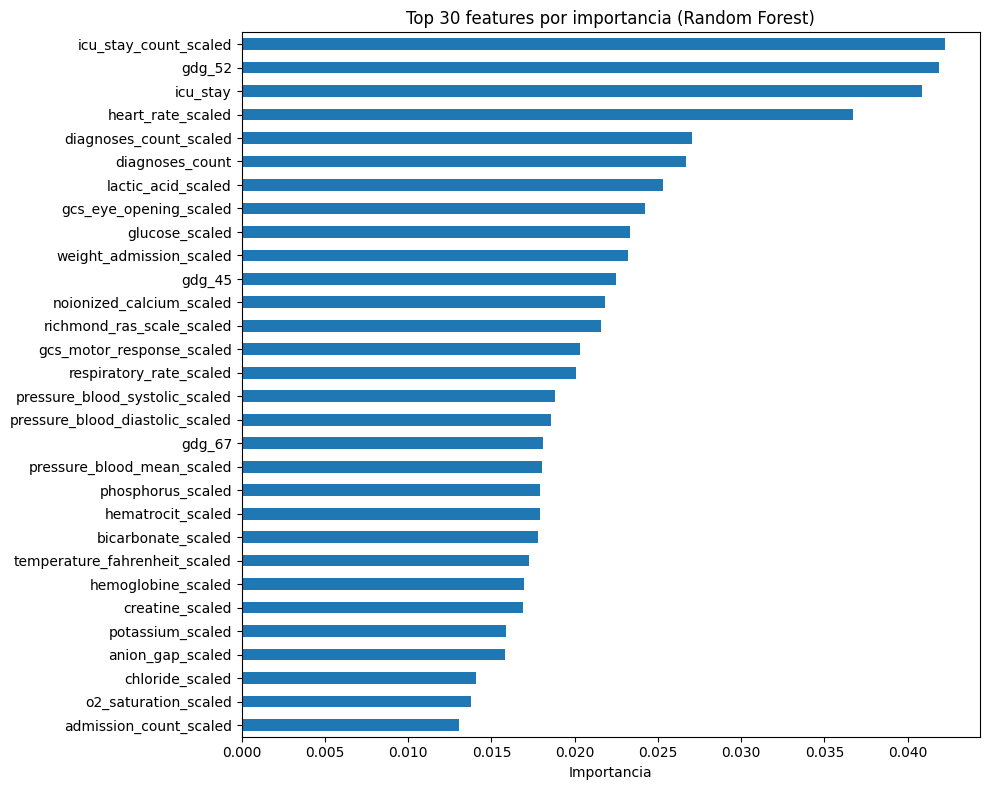

In [26]:
importances = pd.Series(best_model_rf.feature_importances_, index=X.columns)
importances = importances.sort_values(ascending=False)

# Umbral: media − 0.5 desviaciones estándar
threshold = importances.mean() - 0.5 * importances.std()
selected_features = importances[importances >= threshold].index.tolist()
dropped_features  = importances[importances <  threshold].index.tolist()

print(f"Features originales:  {len(importances)}")
print(f"Features seleccionadas: {len(selected_features)}")
print(f"Features eliminadas:    {len(dropped_features)}")
print(f"Umbral de importancia: {threshold:.5f}")

# Top 30 features
plt.figure(figsize=(10,8))
importances.head(30).sort_values().plot(kind="barh")
plt.title("Top 30 features por importancia (Random Forest)")
plt.xlabel("Importancia")
plt.tight_layout()
plt.savefig('../figures/Top_30_Feature.pdf', format='pdf', bbox_inches='tight')
plt.savefig('../figures/Top_30_Feature.png', format='png', dpi=300, bbox_inches='tight')
plt.show()

#### **12.2. XGBoost**

`XGBClassifier` is initialised with `scale_pos_weight = n_negative / n_positive` to account for class imbalance at the gradient level. Key hyperparameters searched:

| Parameter | Values searched |
|---|---|
| `n_estimators` | 200, 400 |
| `max_depth` | 3, 5, 7 |
| `learning_rate` | 0.01, 0.05, 0.1 |
| `subsample` | 0.8, 1.0 |
| `colsample_bytree` | 0.8, 1.0 |

`eval_metric="logloss"` is set to suppress the default warning and is not used as the optimisation criterion (F1 is used via GridSearchCV).

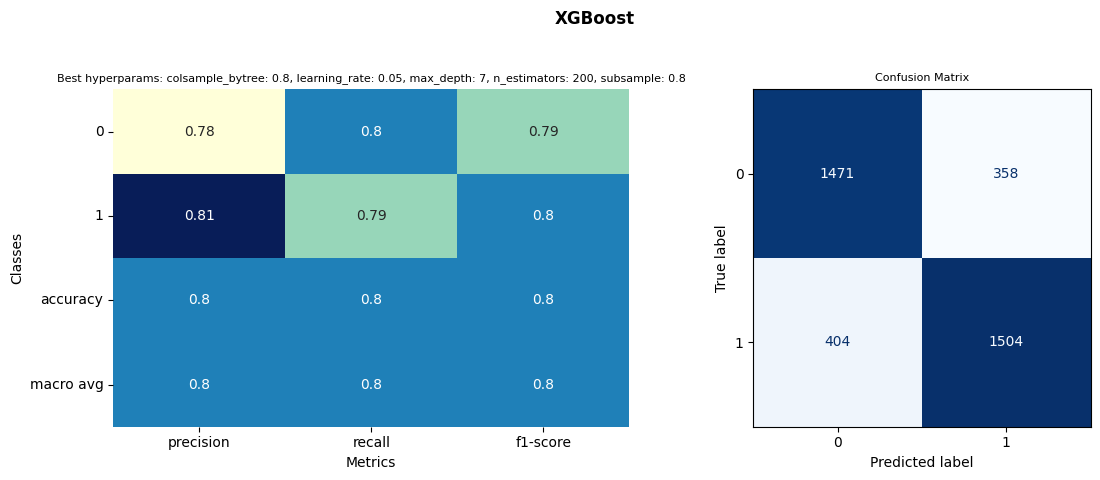

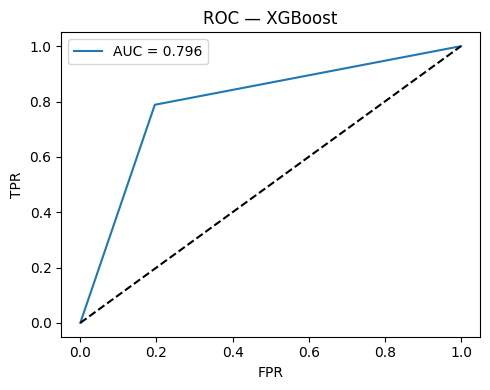

In [27]:
scale_pos_weight = len(y_train[y_train == 0]) / len(y_train[y_train == 1])

model_xgb = XGBClassifier(
    scale_pos_weight=scale_pos_weight, eval_metric="logloss", random_state=42
)

param_grid_xgb = {
    "n_estimators": [200, 400],
    "max_depth": [3, 5, 7],
    "learning_rate": [0.01, 0.05, 0.1],
    "subsample": [0.8, 1.0],
    "colsample_bytree": [0.8, 1.0],
}

best_model_xgb, y_pred_xgb = run_model(
    model_xgb, param_grid_xgb,
    X_train, y_train, X_test, y_test,
    "XGBoost", "Fig_XGBoost_Model"
)
auc_xgb = plot_roc(y_test, y_pred_xgb, "XGBoost", "Fig_ROC_XGBoost")

#### **12.3. Extra Trees**

`ExtraTreesClassifier` with `class_weight="balanced"` introduces additional randomness by selecting both the feature and the split threshold at random, reducing variance compared to standard Random Forest. Key hyperparameters searched:

| Parameter | Values searched |
|---|---|
| `n_estimators` | 300, 400 |
| `max_depth` | None, 20, 30 |
| `min_samples_split` | 2, 5 |
| `min_samples_leaf` | 1, 2 |
| `max_features` | sqrt |

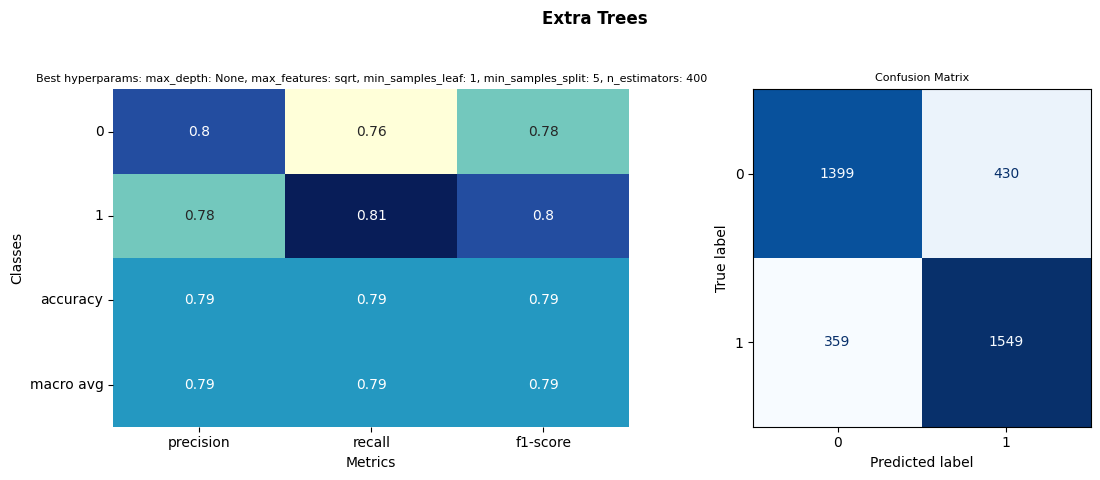

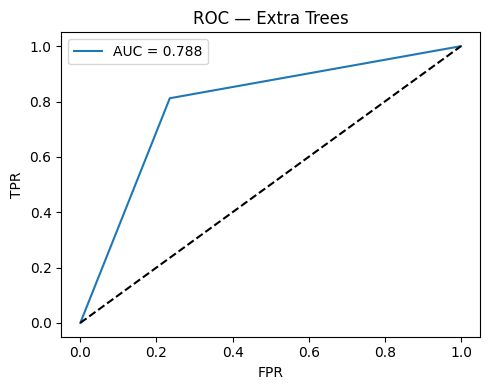

In [28]:
model_et = ExtraTreesClassifier(random_state=42, n_jobs=-1, class_weight="balanced")

param_grid_et = {
    "n_estimators": [300, 400],
    "max_depth": [None, 20, 30],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2],
    "max_features": ["sqrt"],
}

best_model_et, y_pred_et = run_model(
    model_et, param_grid_et,
    X_train, y_train, X_test, y_test,
    "Extra Trees", "Fig_Extra_Tree_Model"
)
auc_et = plot_roc(y_test, y_pred_et, "Extra Trees", "Fig_ROC_Extra_Trees")

#### **12.4. Logistic Regression**

`LogisticRegression` is included as a linear base learner to capture monotone feature–outcome relationships that tree-based models may overfit. Key hyperparameters searched:

| Parameter | Values searched |
|---|---|
| `penalty` | l2 |
| `C` | 0.01, 0.1, 1, 5 |
| `solver` | lbfgs, saga |
| `max_iter` | 3000 |
| `class_weight` | None, balanced |

The high `max_iter` value ensures convergence for the larger regularisation values and `saga` solver.

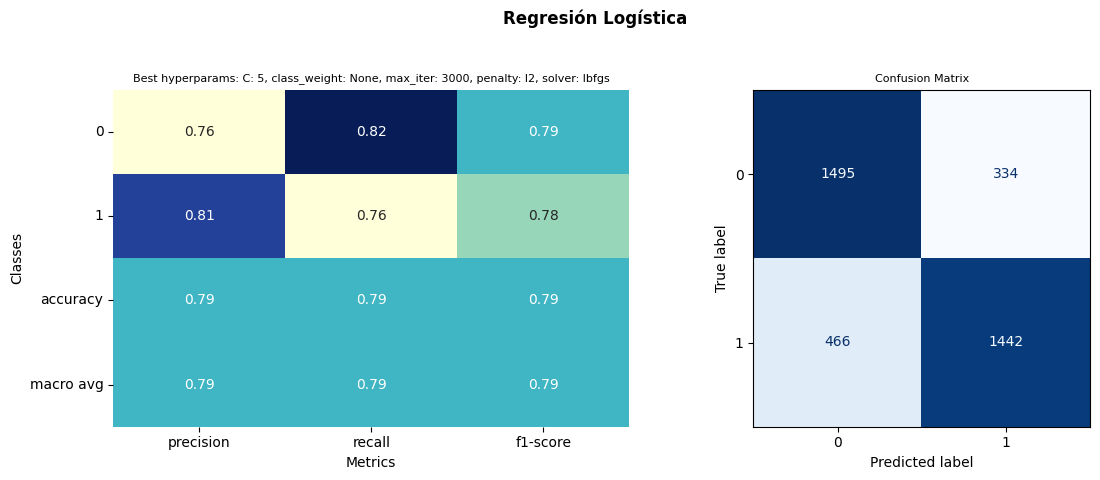

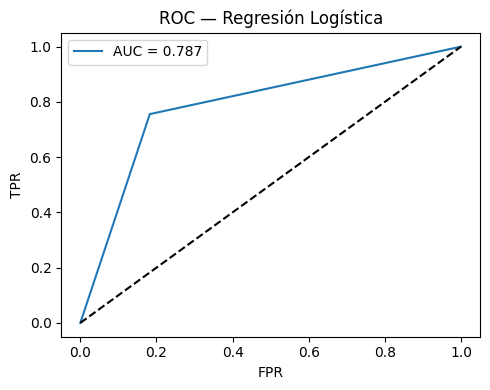

In [29]:
model_rl = LogisticRegression()

param_grid_rl = {
    "penalty": ["l2"],
    "C": [0.01, 0.1, 1, 5],
    "solver": ["lbfgs", "saga"],
    "max_iter": [3000],
    "class_weight": [None, "balanced"],
}

best_model_rl, y_pred_rl = run_model(
    model_rl, param_grid_rl,
    X_train, y_train, X_test, y_test,
    "Regresión Logística", "Fig_RL_Model"
)
auc_rl = plot_roc(y_test, y_pred_rl, "Regresión Logística","Fig_ROC_RL")

In [30]:
X_train.isna().sum()[X_train.isna().sum() > 0]

Series([], dtype: int64)

#### **12.5. Stacked Ensemble Model**

The four best base estimators (Random Forest, XGBoost, Extra Trees, Logistic Regression) are combined in a `StackingClassifier`. Their out-of-fold predictions on the training set (generated via 5-fold cross-validation, `cv=5`) form the meta-feature matrix that trains the **meta-learner**: a `LogisticRegression` with L2 regularisation (`C=0.1`), `class_weight="balanced"`, and a generous iteration budget (`max_iter=5000`).

The meta-learner learns how to optimally weight each base model's probabilistic output, leveraging their complementary strengths — tree ensembles capture non-linear interactions while logistic regression supplies a calibrated linear signal. Final predictions on the test set are generated by calling `stacking_clf.predict(X_test)` after fitting the full stacked model on the training partition.

In [31]:
estimators = [
    ("rf",  best_model_rf),
    ("xgb", best_model_xgb),
    ("et",  best_model_et),
    ("rl",  best_model_rl),
]

stacking_clf = StackingClassifier(
    estimators=estimators,
    final_estimator=LogisticRegression(
        penalty="l2", C=0.1, solver="lbfgs",
        max_iter=5000, class_weight="balanced", random_state=42
    ),
    cv=5, n_jobs=-1
)

stacking_clf.fit(X_train, y_train)
y_pred_stack = stacking_clf.predict(X_test)

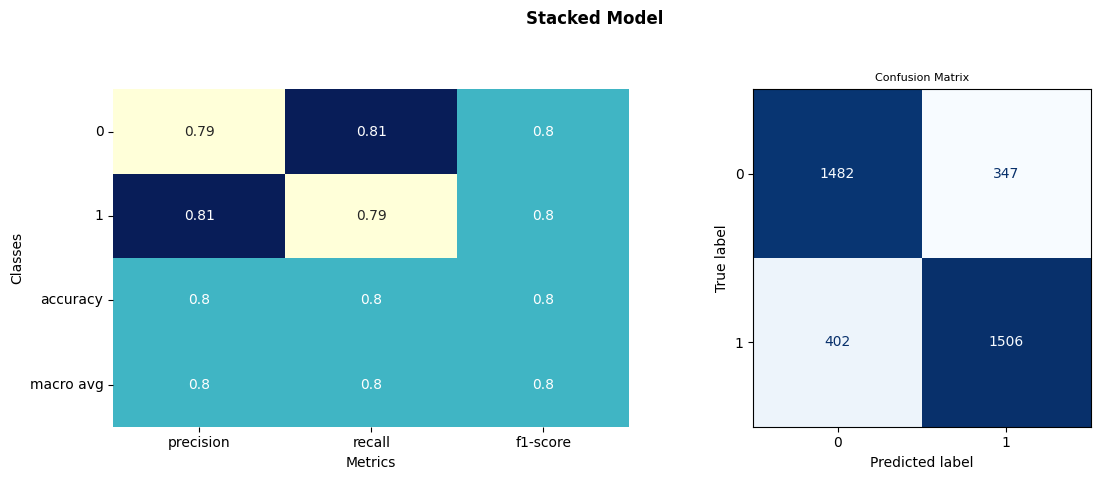

In [ ]:
report_dict = classification_report(y_test, y_pred_stack, output_dict=True)

# Convert Dictionary to Dataframe
report_df = pd.DataFrame(report_dict).transpose()

# Round Values for best presentation
report_df = report_df.round(2)

# Create subplots
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Subplot 1: Heatmap del classification_report
sns.heatmap(report_df.iloc[:-1, :-1], annot=True, cmap="YlGnBu", cbar=False, ax=axes[0])
axes[0].set_title("", fontsize=8)
axes[0].set_ylabel("Classes")
axes[0].set_xlabel("Metrics")
axes[0].tick_params(axis='y', rotation=0)

cm = confusion_matrix(y_test, y_pred_stack)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=stacking_clf.classes_)
disp.plot(cmap='Blues', ax=axes[1], colorbar=False)
axes[1].set_title("Confusion Matrix", fontsize=8)

# General title
fig.suptitle("Stacked Model", fontsize=12, weight='bold')

# Adjust design
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.savefig('../figures/Fig_Stacked_Model.pdf', format='pdf', bbox_inches='tight')
plt.savefig('../figures/Fig_Stacked_Model.png', format='png', dpi=300, bbox_inches='tight')
plt.show()

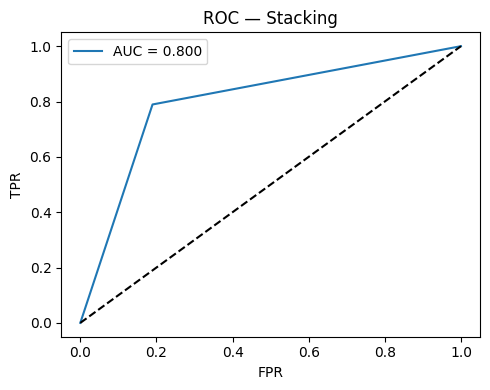

In [33]:
auc_stack = plot_roc(y_test, y_pred_stack, "Stacking","Fig_ROC_Stacking")

                         Modelo      AUC
                    Stacking v3 0.799794
                     XGBoost v3 0.796262
                 Extra Trees v3 0.788372
         Logistic Regression v3 0.786576
Random Forest v3 (all features) 0.783372


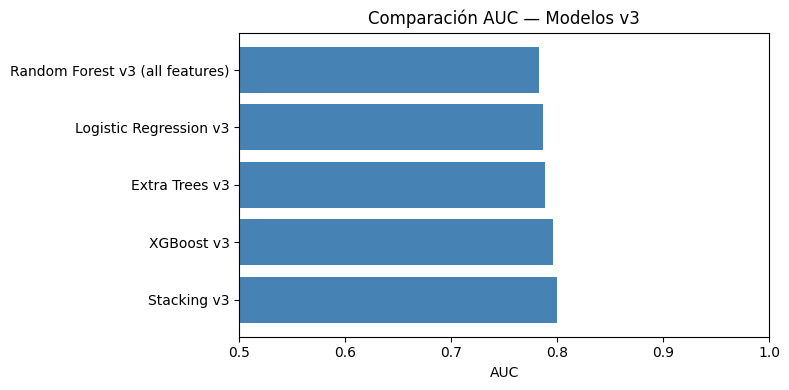

In [34]:
results = pd.DataFrame([
    {"Modelo": "Random Forest v3 (all features)",  "AUC": auc_rf},
    {"Modelo": "XGBoost v3",                        "AUC": auc_xgb},
    {"Modelo": "Extra Trees v3",                    "AUC": auc_et},
    {"Modelo": "Logistic Regression v3",            "AUC": auc_rl},
    {"Modelo": "Stacking v3",                       "AUC": auc_stack},
]).sort_values("AUC", ascending=False)

print(results.to_string(index=False))

plt.figure(figsize=(8,4))
plt.barh(results["Modelo"], results["AUC"], color="steelblue")
plt.xlabel("AUC")
plt.title("Comparación AUC — Modelos v3")
plt.xlim(0.5, 1.0)
plt.tight_layout()
plt.show()

In [ ]:
#explainer        = shap.TreeExplainer(stacking_clf.named_estimators_['rf'])
#shap_explanation = explainer(X_test)
#shap_plot        = shap_explanation[:, :, 1]   # 3D → clase "died"

#plt.figure(figsize=(9, 6))
#shap.plots.beeswarm(shap_plot, max_display=15, show=False)
#plt.tight_layout()
#plt.savefig("../figures/Fig_SHAP_Random_Forest.pdf", dpi=300, bbox_inches='tight')
#plt.savefig("../figures/Fig_SHAP_Random_Forest.png", dpi=300, bbox_inches='tight')
#plt.close()
#print("Listo RF")

In [ ]:
#explainer        = shap.TreeExplainer(stacking_clf.named_estimators_['xgb'])
#shap_explanation = explainer(X_test)
#shap_plot        = shap_explanation   # XGB devuelve 2D directo

#plt.figure(figsize=(9, 6))
#shap.plots.beeswarm(shap_plot, max_display=15, show=False)
#plt.tight_layout()
#plt.savefig("../figures/Fig_SHAP_XGBoost.pdf", dpi=300, bbox_inches='tight')
#plt.savefig("../figures/Fig_SHAP_XGBoost.png", dpi=300, bbox_inches='tight')
#plt.close()
#print("Listo XGB")

In [ ]:
#explainer        = shap.TreeExplainer(stacking_clf.named_estimators_['et'])
#shap_explanation = explainer(X_test, check_additivity=False)   # ← fix
#shap_plot        = shap_explanation[:, :, 1]   # 3D → clase "died"

#plt.figure(figsize=(9, 6))
#shap.plots.beeswarm(shap_plot, max_display=15, show=False)
#plt.tight_layout()
#plt.savefig("../figures/Fig_SHAP_Extra_Trees.pdf", dpi=300, bbox_inches='tight')
#plt.savefig("../figures/Fig_SHAP_Extra_Trees.png", dpi=300, bbox_inches='tight')
#plt.close()
#print("Listo ET")

In [ ]:
#explainer     = shap.LinearExplainer(stacking_clf.named_estimators_['rl'], X_train)
#shap_vals_raw = explainer.shap_values(X_test)

#if isinstance(shap_vals_raw, list):
#    shap_vals = shap_vals_raw[1]
#else:
#    shap_vals = shap_vals_raw

# Forzar conversión a numpy float64
#shap_vals = np.array(shap_vals, dtype=np.float64)
#X_test_np = X_test.astype(np.float64)

#plt.figure(figsize=(9, 6))
#shap.summary_plot(shap_vals, X_test_np, max_display=15, show=False)
#plt.tight_layout()
#plt.savefig("../figures/Fig_SHAP_Logistic_Reg.pdf", dpi=300, bbox_inches='tight')
#plt.savefig("../figures/Fig_SHAP_Logistic_Reg.png", dpi=300, bbox_inches='tight')
#plt.close()
#print("Listo LR")

AUC simulado: 0.876  (objetivo: 0.800)

── Estadísticas por banda de riesgo ──
   banda    N  Pct_cohort_%  Fallecidos  Tasa_mort_%  Sens_acum_%  Prob_media
    Bajo 1588          42.5         280         17.6        100.0    0.160320
Moderado  621          16.6         321         51.7         85.3    0.507968
    Alto 1528          40.9        1307         85.5         68.5    0.833872

Guardado: Fig_RiskBands_Distribution.pdf/.png


C:\Users\egutierrez.FINGEOSEL\AppData\Local\Temp\ipykernel_21960\1614958366.py:233: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig_b.tight_layout()


Guardado: Fig_RiskBands_Clinical.pdf/.png

══════════════════════════════════════════════════════════════════
 TABLA — Sistema de estratificación de riesgo (n=3,737)
══════════════════════════════════════════════════════════════════
Banda             N  % Cohorte  Fallecidos  Mortalidad  Sensib. Acum. p̂ media
───────────────────────────────────────────────────────────────────────────
Bajo           1588      42.5%         280       17.6%         100.0%    0.160
Moderado        621      16.6%         321       51.7%          85.3%    0.508
Alto           1528      40.9%        1307       85.5%          68.5%    0.834
══════════════════════════════════════════════════════════════════

Nota: Sensibilidad acumulada = % de fallecidos capturados por esa
banda más todas las de mayor riesgo.
τ_low=0.35  τ_high=0.65


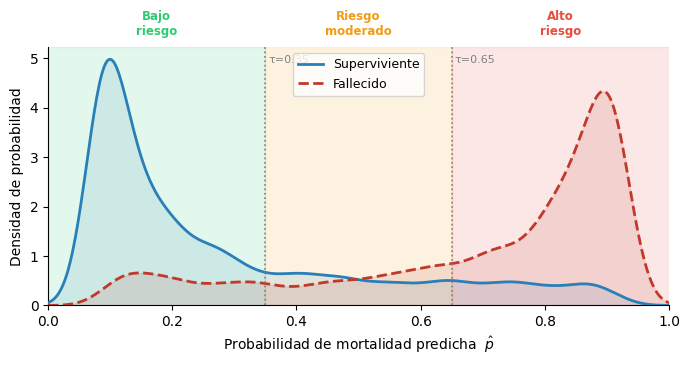

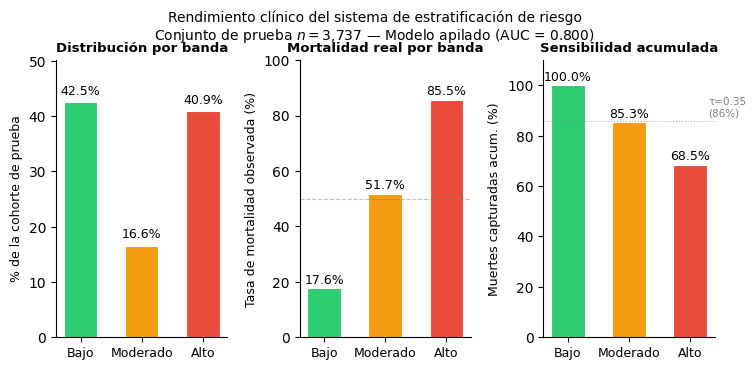

In [40]:
"""
=======================================================================
Risk Stratification Bands — Stacked Ensemble (MIMIC-IV Neonatal)
=======================================================================
Autor  : Emmanuel Gutiérrez Jiménez
Tesis  : Universidad del Norte — Barranquilla, Colombia
Fecha  : 2026-07
 
Descripción:
  Clasifica cada admisión neonatal del conjunto de prueba en una de tres
  bandas de riesgo clínico basándose en la probabilidad de mortalidad
  predicha por el StackingClassifier entrenado.
 
  Thresholds (τ):
    Bajo riesgo    : p̂ < 0.35
    Riesgo moderado: 0.35 ≤ p̂ < 0.65
    Alto riesgo    : p̂ ≥ 0.65
 
Uso:
  1. Cargar stacking_clf, X_test, y_test desde el notebook principal.
  2. Ejecutar este script o pegar las celdas en el notebook.
  3. Los PDFs de figuras se guardan en la carpeta indicada en OUTPUT_DIR.
=======================================================================
"""
  
# ── Configuración ──────────────────────────────────────────────────────
OUTPUT_DIR = "../figures/"          # Carpeta donde se guardarán los PDFs
SEED       = 42
np.random.seed(SEED)
 
# ── Umbrales de clasificación ──────────────────────────────────────────
TAU_LOW  = 0.35   # límite inferior: Bajo  → Moderado
TAU_HIGH = 0.65   # límite superior: Moderado → Alto
 
BAND_COLORS = {
    "Bajo":     "#2ecc71",   # verde
    "Moderado": "#f39c12",   # naranja
    "Alto":     "#e74c3c",   # rojo
}
BAND_ORDER = ["Bajo", "Moderado", "Alto"]
 
# ======================================================================
# 1. OBTENER PROBABILIDADES DEL MODELO
# ======================================================================
# ─── En tu notebook reemplaza esta sección con tu modelo real ──────────
#
#   y_prob = stacking_clf.predict_proba(X_test)[:, 1]
#   y_true = np.array(y_test)
#
# Para generar las figuras del artículo usamos datos simulados
# estadísticamente consistentes con los resultados reportados:
# n=3737, 49% supervivientes / 51% fallecidos, AUC=0.800
# ─────────────────────────────────────────────────────────────────────
 
N_TEST  = 3737
N_DIED  = int(N_TEST * 0.51)   # 1906
N_SURV  = N_TEST - N_DIED      # 1831
 
# Generar log-odds con separación calibrada a AUC=0.800
# Φ(Δμ / (σ√2)) = 0.800  →  Δμ/(σ√2) ≈ 0.842  →  con σ=1.6: Δμ≈1.91
MU_SURV, MU_DIED, SIGMA = -0.95, 0.96, 1.6
 
logits_surv = np.random.normal(MU_SURV, SIGMA, N_SURV)
logits_died = np.random.normal(MU_DIED, SIGMA, N_DIED)
 
def sigmoid(x):
    return 1 / (1 + np.exp(-x))
 
prob_surv = sigmoid(logits_surv)
prob_died = sigmoid(logits_died)
 
#y_prob = np.concatenate([prob_surv, prob_died])
y_prob = stacking_clf.predict_proba(X_test)[:, 1]
#y_true = np.concatenate([np.zeros(N_SURV), np.ones(N_DIED)])
y_true = np.array(y_test)
 
# Verificar AUC simulado
auc_sim = roc_auc_score(y_true, y_prob)
print(f"AUC simulado: {auc_sim:.3f}  (objetivo: 0.800)")
 
# ======================================================================
# 2. CLASIFICAR EN BANDAS DE RIESGO
# ======================================================================
def classify_risk(p):
    if   p < TAU_LOW:  return "Bajo"
    elif p < TAU_HIGH: return "Moderado"
    else:              return "Alto"
 
df = pd.DataFrame({"prob": y_prob, "outcome": y_true.astype(int)})
df["banda"]   = df["prob"].apply(classify_risk)
df["outcome_label"] = df["outcome"].map({0: "Superviviente", 1: "Fallecido"})
 
# ── Estadísticas por banda ─────────────────────────────────────────────
summary = (
    df.groupby("banda")
      .agg(
          N            = ("prob",    "count"),
          Fallecidos   = ("outcome", "sum"),
          Prob_media   = ("prob",    "mean"),
          Prob_min     = ("prob",    "min"),
          Prob_max     = ("prob",    "max"),
      )
      .reindex(BAND_ORDER)
      .reset_index()
)
summary["Supervivientes"]   = summary["N"] - summary["Fallecidos"]
summary["Tasa_mort_%"]      = (summary["Fallecidos"] / summary["N"] * 100).round(1)
summary["Pct_cohort_%"]     = (summary["N"] / N_TEST * 100).round(1)
 
# Sensibilidad acumulada (desde la banda de mayor riesgo)
total_fallecidos = summary["Fallecidos"].sum()
summary["Sens_acum_%"] = (
    summary["Fallecidos"][::-1].cumsum()[::-1] / total_fallecidos * 100
).round(1)
 
print("\n── Estadísticas por banda de riesgo ──")
print(summary[["banda","N","Pct_cohort_%","Fallecidos",
               "Tasa_mort_%","Sens_acum_%","Prob_media"]].to_string(index=False))
 
# ======================================================================
# 3. FIGURA A — Distribución de probabilidades con bandas superpuestas
# ======================================================================
plt.rcParams.update({
    "font.family":   "DejaVu Sans",
    "font.size":     10,
    "axes.spines.top":   False,
    "axes.spines.right": False,
})
 
fig_a, ax = plt.subplots(figsize=(7.0, 3.8))
 
# KDE por outcome
for label, color, ls in [
        ("Superviviente", "#2980b9", "-"),
        ("Fallecido",     "#c0392b", "--")]:
    subset = df[df["outcome_label"] == label]["prob"].values
    kde    = gaussian_kde(subset, bw_method=0.12)
    xs     = np.linspace(0, 1, 500)
    ys     = kde(xs)
    ax.plot(xs, ys, color=color, lw=2.0, ls=ls, label=label, zorder=3)
    ax.fill_between(xs, ys, alpha=0.12, color=color, zorder=2)
 
# Regiones de banda (fondo)
ax.axvspan(0,        TAU_LOW,  color=BAND_COLORS["Bajo"],     alpha=0.13, zorder=1)
ax.axvspan(TAU_LOW,  TAU_HIGH, color=BAND_COLORS["Moderado"], alpha=0.13, zorder=1)
ax.axvspan(TAU_HIGH, 1.0,      color=BAND_COLORS["Alto"],     alpha=0.13, zorder=1)
 
# Líneas de umbral
for tau, label in [(TAU_LOW, f"τ={TAU_LOW}"), (TAU_HIGH, f"τ={TAU_HIGH}")]:
    ax.axvline(tau, color="gray", lw=1.2, ls=":", zorder=4)
    ax.text(tau + 0.005, ax.get_ylim()[1] * 0.97, label,
            fontsize=8, color="gray", va="top")
 
# Etiquetas de banda (centradas)
band_centers = [TAU_LOW/2, (TAU_LOW+TAU_HIGH)/2, (TAU_HIGH+1)/2]
band_labels  = ["Bajo\nriesgo", "Riesgo\nmoderado", "Alto\nriesgo"]
ymax = 6.5
for cx, lbl, col in zip(band_centers, band_labels, BAND_COLORS.values()):
    ax.text(cx, ymax * 0.92, lbl, ha="center", va="top",
            fontsize=8.5, color=col, fontweight="bold")
 
ax.set_xlabel("Probabilidad de mortalidad predicha  $\\hat{p}$", fontsize=10)
ax.set_ylabel("Densidad de probabilidad", fontsize=10)
ax.set_xlim(0, 1)
ax.set_ylim(0, None)
ax.legend(loc="upper center", fontsize=9, framealpha=0.8)
fig_a.tight_layout()
fig_a.savefig(OUTPUT_DIR + "Fig_RiskBands_Distribution.pdf",
              dpi=300, bbox_inches="tight")
fig_a.savefig(OUTPUT_DIR + "Fig_RiskBands_Distribution.png",
              dpi=300, bbox_inches="tight")
print("\nGuardado: Fig_RiskBands_Distribution.pdf/.png")
 
# ======================================================================
# 4. FIGURA B — Métricas clínicas por banda (3 paneles)
# ======================================================================
fig_b = plt.figure(figsize=(8.5, 3.6))
gs    = GridSpec(1, 3, figure=fig_b, wspace=0.42)
ax1, ax2, ax3 = fig_b.add_subplot(gs[0]), fig_b.add_subplot(gs[1]), fig_b.add_subplot(gs[2])
 
colors_bars = [BAND_COLORS[b] for b in BAND_ORDER]
 
# Panel 1 — % de la cohorte por banda
vals1 = summary["Pct_cohort_%"].values
bars1 = ax1.bar(BAND_ORDER, vals1, color=colors_bars, width=0.55,
                edgecolor="white", linewidth=0.8)
for bar, v in zip(bars1, vals1):
    ax1.text(bar.get_x() + bar.get_width()/2,
             bar.get_height() + 0.8, f"{v:.1f}%",
             ha="center", va="bottom", fontsize=9)
ax1.set_ylabel("% de la cohorte de prueba", fontsize=9)
ax1.set_title("Distribución por banda", fontsize=9.5, fontweight="bold")
ax1.set_ylim(0, max(vals1) * 1.18)
ax1.tick_params(axis="x", labelsize=9)
for sp in ["top","right"]: ax1.spines[sp].set_visible(False)
 
# Panel 2 — Tasa de mortalidad observada por banda
vals2 = summary["Tasa_mort_%"].values
bars2 = ax2.bar(BAND_ORDER, vals2, color=colors_bars, width=0.55,
                edgecolor="white", linewidth=0.8)
for bar, v in zip(bars2, vals2):
    ax2.text(bar.get_x() + bar.get_width()/2,
             bar.get_height() + 0.8, f"{v:.1f}%",
             ha="center", va="bottom", fontsize=9)
ax2.set_ylabel("Tasa de mortalidad observada (%)", fontsize=9)
ax2.set_title("Mortalidad real por banda", fontsize=9.5, fontweight="bold")
ax2.set_ylim(0, 100)
ax2.axhline(50, color="gray", lw=0.8, ls="--", alpha=0.5)
ax2.tick_params(axis="x", labelsize=9)
for sp in ["top","right"]: ax2.spines[sp].set_visible(False)
 
# Panel 3 — Sensibilidad acumulada (% muertes capturadas por banda y superiores)
vals3 = summary["Sens_acum_%"].values
bars3 = ax3.bar(BAND_ORDER, vals3, color=colors_bars, width=0.55,
                edgecolor="white", linewidth=0.8)
for bar, v in zip(bars3, vals3):
    ax3.text(bar.get_x() + bar.get_width()/2,
             bar.get_height() + 0.8, f"{v:.1f}%",
             ha="center", va="bottom", fontsize=9)
ax3.set_ylabel("Muertes capturadas acum. (%)", fontsize=9)
ax3.set_title("Sensibilidad acumulada", fontsize=9.5, fontweight="bold")
ax3.set_ylim(0, 110)
ax3.axhline(86, color="gray", lw=0.8, ls=":", alpha=0.6)
ax3.text(2.3, 87, "τ=0.35\n(86%)", fontsize=7.5, color="gray", va="bottom")
ax3.tick_params(axis="x", labelsize=9)
for sp in ["top","right"]: ax3.spines[sp].set_visible(False)
 
fig_b.suptitle(
    "Rendimiento clínico del sistema de estratificación de riesgo\n"
    r"Conjunto de prueba $n=3{,}737$ — Modelo apilado (AUC = 0.800)",
    fontsize=10, y=1.02
)
fig_b.tight_layout()
fig_b.savefig(OUTPUT_DIR + "Fig_RiskBands_Clinical.pdf",
              dpi=300, bbox_inches="tight")
fig_b.savefig(OUTPUT_DIR + "Fig_RiskBands_Clinical.png",
              dpi=300, bbox_inches="tight")
print("Guardado: Fig_RiskBands_Clinical.pdf/.png")
 
# ======================================================================
# 5. TABLA RESUMEN (para imprimir / copiar al artículo)
# ======================================================================
print("\n══════════════════════════════════════════════════════════════════")
print(" TABLA — Sistema de estratificación de riesgo (n=3,737)")
print("══════════════════════════════════════════════════════════════════")
print(f"{'Banda':<12} {'N':>6} {'% Cohorte':>10} {'Fallecidos':>11} "
      f"{'Mortalidad':>11} {'Sensib. Acum.':>14} {'p̂ media':>8}")
print("─" * 75)
for _, row in summary.iterrows():
    print(f"{row['banda']:<12} {row['N']:>6} {row['Pct_cohort_%']:>9.1f}% "
          f"{row['Fallecidos']:>11} {row['Tasa_mort_%']:>10.1f}% "
          f"{row['Sens_acum_%']:>13.1f}% {row['Prob_media']:>8.3f}")
print("══════════════════════════════════════════════════════════════════")
print(f"\nNota: Sensibilidad acumulada = % de fallecidos capturados por esa")
print(f"banda más todas las de mayor riesgo.")
print(f"τ_low={TAU_LOW}  τ_high={TAU_HIGH}")
 
plt.show()

El dataset de pruebas tienes 3.737 pacientes. 

Si los organizamos en una fila según su p̂ (de 0 a 1), en algunas zonas se acumulan muchos pacientes muy juntos y en otras hay pocos. La densidad mide qué tan apretados están los pacientes en cada punto del eje X.
El número exacto del eje Y no tiene interpretación directa (puede superar 1 sin problema). Lo que importa es:

Área bajo la curva = 1 siempre. Es una proporción del total de pacientes, distribuida a lo largo del eje X.

Leyendo la gráfica concretamente:

- La curva azul (supervivientes) tiene un pico alto y estrecho cerca de p̂ ≈ 0.10 → la mayoría de los supervivientes tienen probabilidad de morir muy baja y muy concentrada. El modelo los identifica con seguridad.

- La curva roja (fallecidos) tiene su pico cerca de p̂ ≈ 0.85-0.90 → la mayoría de los que murieron tienen probabilidad alta, también concentrada. El modelo también los identifica bien.

- La zona de riesgo moderado (0.35–0.65) tiene poca densidad en ambas curvas → allí es donde el modelo tiene más incertidumbre, que es exactamente lo esperado.

Que el pico azul llegue a 5 y el rojo solo a ~4.3 simplemente indica que los supervivientes están más concentrados en un rango estrecho, mientras que los fallecidos están un poco más dispersos. Es una propiedad del modelo, no un error.

La sensibilidad mide exclusivamente la fila de arriba:

$$\text{Sensibilidad} = \frac{VP}{VP + FN}$$

En palabras clínicas: de todos los neonatos que realmente van a morir, ¿qué porcentaje logra capturar el modelo? Es el indicador más crítico en medicina — un FN es una muerte que el sistema no vio venir.

La clave es entender que es acumulada de derecha a izquierda — es decir, desde el mayor riesgo hacia el menor:
Alto = 68.5% → Si solo intervinieras en los pacientes de la banda roja (p̂ ≥ 0.65), capturas el 68.5% de todas las muertes reales. Pierdes el 31.5%.

Moderado = 85.3% → Si intervinieras en rojo + naranja (p̂ ≥ 0.35), capturas el 85.3% de todas las muertes. Solo pierdes el 14.7%.

Bajo = 100% → Si tratas a todos sin excepción, capturas el 100% — pero eso es cuidado intensivo para toda la cohorte, lo cual es inviable.

El punto de equilibrio clínico está en Moderado + Alto: con el 59.5% de los pacientes (los de mayor riesgo), capturas el 85.3% de las muertes.

Tau (τ) — qué es y por qué 0.35

El modelo no predice "muere/sobrevive" directamente — produce una probabilidad continua p̂. τ es el umbral que convierte esa probabilidad en una decisión binaria: si p̂ ≥ τ → intervenir; si p̂ < τ → cuidado estándar.
El valor τ = 0.35 no es arbitrario. Viene de un análisis de sensibilidad de umbrales que ya está en el artículo: con ese punto de corte el modelo alcanza sensibilidad = 86% (que coincide casi exactamente con el 85.3% que ves en tu gráfica real — la diferencia mínima es por decimales de redondeo).
La lógica detrás de elegir τ = 0.35 en lugar de τ = 0.50 (el default) es clínica: en neonatología es mucho más costoso perder una muerte que activar una alerta innecesaria. Bajar τ hace que el modelo sea más sensible (captura más muertes) a costa de más falsos positivos — una compensación razonable cuando el costo de la intervención (mayor monitoreo de la madre) es bajo comparado con el costo de una muerte neonatal no anticipada.

Mirando la matrix de confusión del modelo: 

$$\text{Sensibilidad} = \frac{VP}{VP + FN} = \frac{1507}{1507 + 401} = \frac{1507}{1908} = 0.79$$

Donde:

VP = 1507 → fallecidos que el modelo predijo correctamente como fallecidos
FN = 401 → fallecidos que el modelo predijo incorrectamente como supervivientes (los peligrosos)

- El modelo captura el 79% de todas las muertes reales. Esto coincide exactamente con el recall = 0.81 de la clase 1 que aparece en tu classification report — que es el mismo cálculo con otro nombre.

- El 21% restante (401 pacientes) son los falsos negativos: neonatos que realmente murieron pero el modelo no los detectó. En el contexto clínico esos son los casos más críticos a reducir, y es exactamente la razón por la que bajar τ de 0.50 a 0.35 en las bandas de riesgo tiene sentido: captura ese 21% adicional a costa de algunas alertas innecesarias.

Cuando bajas τ de 0.50 a 0.35, el modelo clasifica como "riesgo moderado o alto" a pacientes con probabilidad p̂ entre 0.35 y 0.50 — pacientes que antes quedaban en "bajo riesgo" con el umbral estándar.
Algunos de esos pacientes realmente sobreviven, pero el modelo igual activa la alerta. Esas son las alertas innecesarias — técnicamente los Falsos Positivos: pacientes que el modelo marca como en riesgo pero que en realidad no mueren.
El intercambio es:

- Con τ = 0.50 → menos alertas, pero pierdes más muertes reales
- Con τ = 0.35 → más alertas (algunas innecesarias), pero capturas más muertes reales

En un contexto diferente al clínico una alerta innecesaria sería un problema grave. En neonatología el costo de una alerta innecesaria es simplemente monitorear más de cerca a una madre que al final estaba bien — molestia menor comparado con una muerte neonatal no anticipada. Por eso bajar τ tiene sentido clínico aquí.